# **AI203 Final Project : NBA shot log**
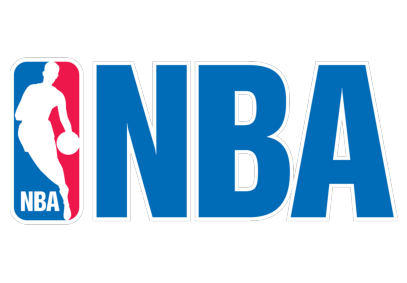

**By Students of B10 section Data mining by Dr.Soha Ahmed & Eng.Huda Hemdan:**

**1.** Jumana Saeed Abd Elkhalik  (EDA & Documentation)

**2.** Salma Khaled Mohammed   (Cleaning , Association & Documentation)

**3.** Asmaa Essam Elgammal      (Clustring, Classification & Model Evaluation)

**4.** Hamsa Mustafa Aboelghit                     (EDA)

**5.** Shahd gomaa ali           (Cleaning)

**6.** Shoruok Mohamed Adel      (Model Evaluation)



# **Step 1 — Understanding the Project and Setting Objectives**

# **- Problem Statement**

---



The NBA is one of the most data-rich sports leagues in the world, generating thousands of shot attempts every single game. Despite this abundance of data, coaches and analysts often rely on intuition rather than evidence when making decisions about shot selection, defensive strategy, and player evaluation.

This project analyzes **128,069 real NBA shot attempts** from the 2014–15 season to answer a critical question: *what actually determines whether a shot goes in?* By applying data mining and machine learning techniques, we aim to uncover hidden patterns in player shooting behavior, predict shot outcomes before they happen, and group players by their shooting style.

Here's the complete updated nested list with everything included:
markdown- **Target Variable & Input Features**
  - **Numerical**
    - SHOT_DIST — distance from basket (ft)
    - CLOSE_DEF_DIST — distance to defender (ft)
    - FINAL_MARGIN — final score difference
    - SHOT_CLOCK — seconds left on shot clock
    - TOUCH_TIME — seconds player held the ball
    - DRIBBLES — dribbles before shooting
    - SHOT_NUMBER — shot sequence number in the game
    - PERIOD — quarter the shot was taken in
  - **Categorical / String**
    - LOCATION — Home (H) or Away (A)
    - W — Won (W) or Lost (L)
    - SHOT_RESULT — made / missed
    - CLOSEST_DEFENDER — defender's name
    - player_name — shooter's name
    - MATCHUP — date + teams string (e.g. 'MAR 04, 2015 - CHA @ BKN')
    - GAME_CLOCK — time remaining in quarter (stored as 'MM:SS' string)
    - PTS_TYPE — 2-pointer or 3-pointer
  - **Boolean**
    - FGM — 1 = made, 0 = missed **(TARGET)**
    - W — also interpretable as boolean (1 = won, 0 = lost)
  - **Numerical (derived / points)**
    - PTS — points scored (0, 2, or 3)
  - **ID / Administrative**
    - GAME_ID — unique game identifier
    - player_id — shooter's ID
    - CLOSEST_DEFENDER_PLAYER_ID — defender's ID

# **Project Goals**

- Predict whether an NBA shot will be made or missed using machine learning classification models trained on shot distance, defender proximity, and game context features.

- Discover hidden shooting archetypes among NBA players by applying K-Means clustering to group players based on their shooting behavior and style.

- Identify which court zones and conditions produce the highest shooting efficiency to provide data-driven recommendations for coaches and analysts.

- Uncover frequent patterns in shooting behavior using association rule mining to find combinations of factors that consistently lead to shot success or failure.

#**🏀 TOP 10 MOST IMPORTANT QUESTIONS ANSWERED BY OUR NBA PROJECT:**

#**1. From which court zones do players score most efficiently?**

**ANSWER**: Paint (<8ft): `56.6%` > Mid-Range: `40.3%` > 3PT: `35.1%`

**IMPACT**: Prioritize paint touches over jumpers

---

#**2. Can we predict shots BEFORE they happen?**

**ANSWER**: YES - Random Forest: **55.5% accuracy** (beats 45.2% baseline)

**IMPACT**: Real-time shot quality scouting

---

#**3. How does defender distance affect makes?**

**ANSWER**: Contested (2-4ft): **46.9%** > Open: 43.7% (counterintuitive!)

**IMPACT**: Smart shot selection > just "open" looks

---

#**4. What are the 4 NBA player shooting styles?**

**ANSWER**: Paint Scorers (57%) | 3PT Shooters | Mid-Range | Versatile

**IMPACT**: Optimal lineup construction

---

#**5. Which players beat their shot difficulty?**

**ANSWER**: Gortat (54.6%) | Davis (54.3%) | Horford (54.1%)

**IMPACT**: Identify elite finishers for crunch time

---

#**6. Home court advantage = real?**

**ANSWER**: **YES** - Home: 45.6% vs Away: 44.8% (+0.8%)

**IMPACT**: Schedule/travel optimization

---

#**7. Top 3 factors predicting shot success?**

**ANSWER**: 1. Distance (42-62%) | 2. Defender (28-30%) | 3. Shot Type

**IMPACT**: Defensive scouting priorities

---

#**8. Do teams get tired (period-by-period)?**

**ANSWER**: Slight Q1→Q4 drop-off, OT rebounds

**IMPACT**: Rotation & fatigue management

---

#**9. Does dribbling hurt shooting?**

**ANSWER**: **YES** - 0 dribbles > 1+ dribbles

**IMPACT**: Promote catch-and-shoot offense

---

#**10. Best lineup combo?**

**ANSWER**: Paint Scorer + 3PT Shooter

**IMPACT**: Forces ultimate defensive dilemma

---


# **Step 2 — Data Collection & Exploration**

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [ ]:
#importing the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.patches as mpatches
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)


In [ ]:
NBA_shot_log = pd.read_csv("/content/shot_logs.csv")
NBA_shot_log.head()

,GAME_ID,MATCHUP,LOCATION,W,FINAL_MARGIN,SHOT_NUMBER,PERIOD,GAME_CLOCK,SHOT_CLOCK,DRIBBLES,...,SHOT_DIST,PTS_TYPE,SHOT_RESULT,CLOSEST_DEFENDER,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,FGM,PTS,player_name,player_id
0,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,1,1,1:09,10.8,2,...,7.7,2,made,"Anderson, Alan",101187,1.3,1,2,brian roberts,203148
1,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,2,1,0:14,3.4,0,...,28.2,3,missed,"Bogdanovic, Bojan",202711,6.1,0,0,brian roberts,203148
2,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,3,1,0:00,NaN,3,...,10.1,2,missed,"Bogdanovic, Bojan",202711,0.9,0,0,brian roberts,203148
3,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,4,2,11:47,10.3,2,...,17.2,2,missed,"Brown, Markel",203900,3.4,0,0,brian roberts,203148
4,21400899,"MAR 04, 2015 - CHA @ BKN",A,W,24,5,2,10:34,10.9,2,...,3.7,2,missed,"Young, Thaddeus",201152,1.1,0,0,brian roberts,203148


In [ ]:
#shape of data (rows,columns)
NBA_shot_log.shape

(128069, 21)

In [ ]:
#data columns
NBA_shot_log.columns

Index(['GAME_ID', 'MATCHUP', 'LOCATION', 'W', 'FINAL_MARGIN', 'SHOT_NUMBER',
       'PERIOD', 'GAME_CLOCK', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME',
       'SHOT_DIST', 'PTS_TYPE', 'SHOT_RESULT', 'CLOSEST_DEFENDER',
       'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'FGM', 'PTS',
       'player_name', 'player_id'],
      dtype='object')

In [ ]:
#Information about columns
NBA_shot_log.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128069 entries, 0 to 128068
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   GAME_ID                     128069 non-null  int64  
 1   MATCHUP                     128069 non-null  object 
 2   LOCATION                    128069 non-null  object 
 3   W                           128069 non-null  object 
 4   FINAL_MARGIN                128069 non-null  int64  
 5   SHOT_NUMBER                 128069 non-null  int64  
 6   PERIOD                      128069 non-null  int64  
 7   GAME_CLOCK                  128069 non-null  object 
 8   SHOT_CLOCK                  122502 non-null  float64
 9   DRIBBLES                    128069 non-null  int64  
 10  TOUCH_TIME                  128069 non-null  float64
 11  SHOT_DIST                   128069 non-null  float64
 12  PTS_TYPE                    128069 non-null  int64  
 13  SHOT_RESULT   

In [ ]:
#describe numeric values
NBA_shot_log.describe()

,GAME_ID,FINAL_MARGIN,SHOT_NUMBER,PERIOD,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,SHOT_DIST,PTS_TYPE,CLOSEST_DEFENDER_PLAYER_ID,CLOSE_DEF_DIST,FGM,PTS,player_id
count,1.280690e+05,128069.000000,128069.000000,128069.000000,122502.000000,128069.000000,128069.000000,128069.000000,128069.000000,128069.000000,128069.000000,128069.000000,128069.000000,128069.000000
mean,2.140045e+07,0.208723,6.506899,2.469427,12.453344,2.023355,2.765901,13.571504,2.264670,159038.487284,4.123015,0.452139,0.997314,157238.251247
std,2.578773e+02,13.233267,4.713260,1.139919,5.763265,3.477760,3.043682,8.888964,0.441159,78791.172947,2.756446,0.497706,1.130978,79362.389336
min,2.140000e+07,-53.000000,1.000000,1.000000,0.000000,0.000000,-163.600000,0.000000,2.000000,708.000000,0.000000,0.000000,0.000000,708.000000
25%,2.140023e+07,-8.000000,3.000000,1.000000,8.200000,0.000000,0.900000,4.700000,2.000000,101249.000000,2.300000,0.000000,0.000000,101162.000000
50%,2.140045e+07,1.000000,5.000000,2.000000,12.300000,1.000000,1.600000,13.700000,2.000000,201949.000000,3.700000,0.000000,0.000000,201939.000000
75%,2.140067e+07,9.000000,9.000000,3.000000,16.675000,2.000000,3.700000,22.500000,3.000000,203079.000000,5.300000,1.000000,2.000000,202704.000000
max,2.140091e+07,53.000000,38.000000,7.000000,24.000000,32.000000,24.900000,47.200000,3.000000,530027.000000,53.200000,1.000000,3.000000,204060.000000


- **GAME_ID / player_id / CLOSEST_DEFENDER_PLAYER_ID** — these are ID columns. Their statistics (mean, std) have no real meaning.


---


- **FINAL_MARGIN** — min is **-53**, max is **+53**. Negative values are **valid** — they represent the losing margin, not errors as FINAL_MARGIN = shooter's team final score minus opponent's score.


---


- **PERIOD** — max is **7**, meaning some games went to triple overtime.


---


- **SHOT_CLOCK** — count is 122,502 (not 128,069), meaning **5,567 missing values** exist. This is the only column with nulls.


---


- **DRIBBLES** — max is **32**, which is a statistical outlier. Most shots happen on 0–2 dribbles (median = 1).


---


- **TOUCH_TIME** — min is **-163.6 seconds**, which is physically impossible. This is corrupted data that needs to be fixed.


---


- **CLOSE_DEF_DIST** — max is **53.2 feet** (roughly half a court). Extreme but physically valid (buzzer-beater heaves) which means attempts from +36 feet.



---



# **Step 3 — Data Cleaning**

# **Fixing Nulls**


---


**SHOT_CLOCK** null means the shot clock was NOT running — this happens at:
 - End of a quarter (clock already expired, no shot clock shown)
 - Inbound plays / jump balls (clock not started yet)
 - Fast-break situations (sometimes not captured)

 Filling with **mean (~12.5s)** would **LIE** to the model — it would think those shots happened with 12 seconds left, hiding their special context.


---



**Filling with -1** creates a **SENTINEL** value:
 - It's outside the **valid [0, 24] range**, so the model can recognise it and preserves the information that these are **special situations**.


---


**WHY NOT drop these rows?**
 - We'd lose 5,567 rows (4.35%) — not huge, but dropping them would create a **biased dataset**.


---



In [ ]:
#Check for nulls
NBA_shot_log.isnull().sum()

,0
GAME_ID,0
MATCHUP,0
LOCATION,0
W,0
FINAL_MARGIN,0
SHOT_NUMBER,0
PERIOD,0
GAME_CLOCK,0
SHOT_CLOCK,5567
DRIBBLES,0


In [ ]:
NBA_shot_log['SHOT_CLOCK'] = NBA_shot_log['SHOT_CLOCK'].fillna(-1)

#confirm that nulls have been replaced
print("SHOT_CLOCK nulls remaining:", NBA_shot_log['SHOT_CLOCK'].isnull().sum())

SHOT_CLOCK nulls remaining: 0


# **Fixing Duplicates**


---


we need to check for exact **duplicate rows** as they silently bias models


---



In [ ]:
duplicates_count = NBA_shot_log.duplicated().sum()
print("Duplicate rows:",duplicates_count)

Duplicate rows: 0


However, the dataset contains **duplicate information across columns**:
- `SHOT_RESULT` ('made'/'missed') and `FGM` (1/0) encode the exact same information
- `PTS` is mathematically derived from `FGM × PTS_TYPE` — no new information
- `CLOSEST_DEFENDER` (name string) and `CLOSEST_DEFENDER_PLAYER_ID` (integer) refer to the same person
- `player_name` (string) and `player_id` (integer) refer to the same player

These are **redundant columns**, not duplicate rows.

In [ ]:
NBA_shot_log = NBA_shot_log.drop('SHOT_RESULT', axis=1)

print("Columns after dropping SHOT_RESULT:")
print(NBA_shot_log.columns)

Columns after dropping SHOT_RESULT:
Index(['GAME_ID', 'MATCHUP', 'LOCATION', 'W', 'FINAL_MARGIN', 'SHOT_NUMBER',
       'PERIOD', 'GAME_CLOCK', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME',
       'SHOT_DIST', 'PTS_TYPE', 'CLOSEST_DEFENDER',
       'CLOSEST_DEFENDER_PLAYER_ID', 'CLOSE_DEF_DIST', 'FGM', 'PTS',
       'player_name', 'player_id'],
      dtype='object')


## **converting GAME_CLOCK from string 'MM:SS' to integer seconds**


---


Machine learning models cannot understand strings like '11:47'.



- We need a numeric representation. **Seconds** preserves full precision ('1:09' = 69, '1:00' = 60) and **Integer** is cleaner than float (0.9833... minutes)

In [ ]:
def convert_to_seconds(time_str):
    m, s = map(int, time_str.split(':'))
    return m * 60 + s

NBA_shot_log['GAME_CLOCK_SEC'] = NBA_shot_log['GAME_CLOCK'].apply(convert_to_seconds)
NBA_shot_log = NBA_shot_log.drop('GAME_CLOCK', axis=1)

print("GAME_CLOCK converted to GAME_CLOCK_SEC (integer seconds)")
print("Sample:", NBA_shot_log['GAME_CLOCK_SEC'].head(5).tolist())

GAME_CLOCK converted to GAME_CLOCK_SEC (integer seconds)
Sample: [69, 14, 0, 707, 634]


## **Columns to encode: LOCATION (A/H) and W (W/L)**


---


**WHY binary map** instead of pd.get_dummies()?
 - Both columns have exactly 2 values — they are already **BINARY**.
 - **get_dummies()** on a binary column creates TWO columns (0 and 1) where one is perfectly the inverse of the other → multicollinearity. **BUT** a single 0/1 map gives all the information with **half the columns**.


---



# **Encoding**


---


 -- **LOCATION:**
 - 'A' = Away → 0  (Away team typically has disadvantage)
 - 'H' = Home → 1  (Home team has crowd advantage)



---



 -- **W:**
 - 'W' = Won  → 1
 - 'L' = Lost → 0


---



In [ ]:
NBA_shot_log['LOCATION'] = NBA_shot_log['LOCATION'].map({'A': 0, 'H': 1})
NBA_shot_log['W']        = NBA_shot_log['W'].map({'W': 1, 'L': 0})

print("LOCATION unique values:", NBA_shot_log['LOCATION'].unique())
print("W unique values:", NBA_shot_log['W'].unique())

LOCATION unique values: [0 1]
W unique values: [1 0]


# **Fixing negative values in TOUCH_TIME**


---


 - The minimum is **-163.6** — physically impossible!
 - **TOUCH_TIME** = how many seconds a player held the ball before shooting.
 - A negative touch time has **NO basketball meaning** — it's a data entry error.


---



In [ ]:
print("TOUCH_TIME statistics:")
print(NBA_shot_log['TOUCH_TIME'].describe())
print()

TOUCH_TIME statistics:
count    128069.000000
mean          2.765901
std           3.043682
min        -163.600000
25%           0.900000
50%           1.600000
75%           3.700000
max          24.900000
Name: TOUCH_TIME, dtype: float64



In [ ]:
negative_count = (NBA_shot_log['TOUCH_TIME'] < 0).sum()
print("Rows with negative TOUCH_TIME:" ,negative_count)

Rows with negative TOUCH_TIME: 312


# **Using IQR for TOUCH_TIME**


---


TOUCH_TIME has issues on **BOTH** ends:
 - **Lower end:** negative values (-163.6s) → physically impossible, corrupt
 - **Upper end:** extreme hold times → statistically distorting

**Why IQR?** It catches both lower **AND** upper outliers in one consistent method


---


── **Step 1:Remove corrupt negatives first** ── (must do this BEFORE IQR, so they don't drag Q1 down and break the fence)


---


── **Step 2: Compute IQR fence** ──


---
── **Step 3: Cap values above the fence** ──


---

── **Step 4: Fill the 312 nulls (from negatives) with median** ──


---



In [ ]:
#Step 1:
NBA_shot_log['TOUCH_TIME'] = NBA_shot_log['TOUCH_TIME'].where(NBA_shot_log['TOUCH_TIME'] >= 0, other=np.nan)

# ── Step 2: Compute IQR fence ──
Q1 = NBA_shot_log['TOUCH_TIME'].quantile(0.25)
Q3 = NBA_shot_log['TOUCH_TIME'].quantile(0.75)
IQR = Q3 - Q1
upper_fence = Q3 + 3 * IQR

print(f"Q1 = {Q1}s | Q3 = {Q3}s | IQR = {IQR}s")
print(f"Upper fence = {upper_fence}s")
print(f"Rows to be capped: {(NBA_shot_log['TOUCH_TIME'] > upper_fence).sum():,}")

# ── Step 3: Cap values above the fence ──
NBA_shot_log['TOUCH_TIME'] = NBA_shot_log['TOUCH_TIME'].clip(upper=upper_fence)

# ── Step 4: Fill the 312 nulls (from negatives) with median ──
touch_median = NBA_shot_log['TOUCH_TIME'].median()
NBA_shot_log['TOUCH_TIME'] = NBA_shot_log['TOUCH_TIME'].fillna(touch_median)

print(f"\nDone! New range: 0 → {NBA_shot_log['TOUCH_TIME'].max():.1f}s")
print(f"Nulls remaining: {NBA_shot_log['TOUCH_TIME'].isnull().sum()}")

Q1 = 0.9s | Q3 = 3.7s | IQR = 2.8000000000000003s
Upper fence = 12.100000000000001s
Rows to be capped: 2,480

Done! New range: 0 → 12.1s
Nulls remaining: 0


# **Using IQR for DRIBBLES**


---


**WHY** cap DRIBBLES and not drop those rows or leave them?


---


DRIBBLES is **heavily right-skewed**: most shots (50%) happen on **0 dribbles (catch-and-shoot)**, but some players dribble 30+ times before shooting.These extreme values are **REAL basketball events (not errors)**, but they are statistical outliers that can:
 -  Distort **linear model** coefficients
 - Force tree models to make unnecessary splits deep in **rare territory**


---
 → **We use 3×IQR (not the classic 1.5×IQR) because:**
- DRIBBLES has legitimate high values (isolation plays)
- 1.5×IQR would cap too aggressively and remove real patterns
- 3×IQR only catches extreme extremes


---

**WHY cap (clip) instead of dropping or replacing with median?**
 - **Dropping:** loses valid rows where only DRIBBLES is extreme
 - **Median replacement:** loses direction (we still know it was high)
 - **Clipping at the fence:** compresses extreme values to the boundary,preserving the 'this was a high-dribble shot' signal while removing the distortion from extreme values


---



In [ ]:
print("DRIBBLES describe:")
print(NBA_shot_log['DRIBBLES'].describe())
print()
print("Top 10 value counts:")
print(NBA_shot_log['DRIBBLES'].value_counts().head(10))

DRIBBLES describe:
count    128069.000000
mean          2.023355
std           3.477760
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          32.000000
Name: DRIBBLES, dtype: float64

Top 10 value counts:
DRIBBLES
0    63195
1    19409
2    13860
3     7790
4     5199
5     3684
6     2843
7     2308
8     1884
9     1534
Name: count, dtype: int64


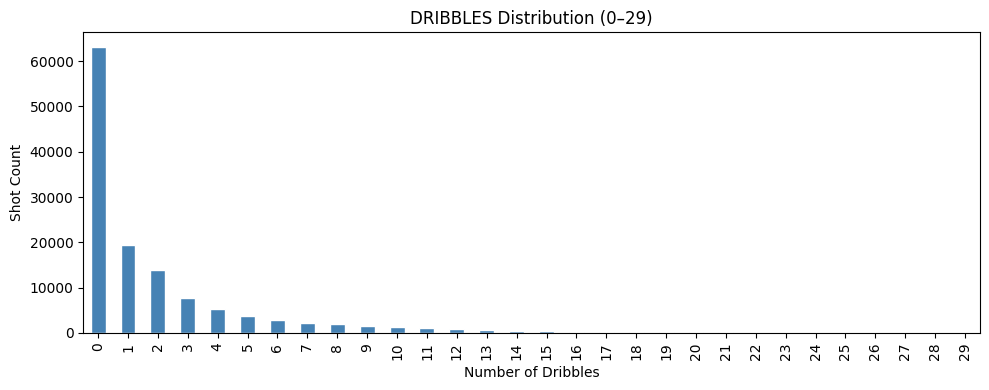

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
NBA_shot_log['DRIBBLES'].value_counts().sort_index().head(30).plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('DRIBBLES Distribution (0–29)')
ax.set_xlabel('Number of Dribbles')
ax.set_ylabel('Shot Count')
plt.tight_layout()
plt.show()

In [ ]:
Q1 = NBA_shot_log['DRIBBLES'].quantile(0.25)
Q3 = NBA_shot_log['DRIBBLES'].quantile(0.75)
IQR = Q3 - Q1
upper_fence = Q3 + 3 * IQR

print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Upper fence (Q3 + 3×IQR): {upper_fence}")
print(f"Rows that will be capped: {(NBA_shot_log['DRIBBLES'] > upper_fence).sum():,}")

NBA_shot_log['DRIBBLES'] = NBA_shot_log['DRIBBLES'].clip(upper=upper_fence)

print(f"\nDRIBBLES capped at {upper_fence}.")
print(f"New max: {NBA_shot_log['DRIBBLES'].max()}")

Q1=0.0, Q3=2.0, IQR=2.0
Upper fence (Q3 + 3×IQR): 8.0
Rows that will be capped: 7,897

DRIBBLES capped at 8.0.
New max: 8


# **Inspect CLOSE_DEF_DIST Outliers**


---


**WHY we do NOT cap CLOSE_DEF_DIST?**
Unlike **DRIBBLES** (where a 50-dribble shot is statistically impossible under game pressure), a 53-foot defender distance is **a real, documented basketball scenario (buzzer-beater heaves).**


---



In [ ]:
#CLOSE_DEF_DIST = distance (feet) between the shooter and nearest defender
print("CLOSE_DEF_DIST statistics:")
print(NBA_shot_log['CLOSE_DEF_DIST'].describe())
print()
print(f"99th percentile: {NBA_shot_log['CLOSE_DEF_DIST'].quantile(0.99):.1f} ft")
print(f"Maximum value: {NBA_shot_log['CLOSE_DEF_DIST'].max():.1f} ft")

CLOSE_DEF_DIST statistics:
count    128069.000000
mean          4.123015
std           2.756446
min           0.000000
25%           2.300000
50%           3.700000
75%           5.300000
max          53.200000
Name: CLOSE_DEF_DIST, dtype: float64

99th percentile: 14.1 ft
Maximum value: 53.2 ft


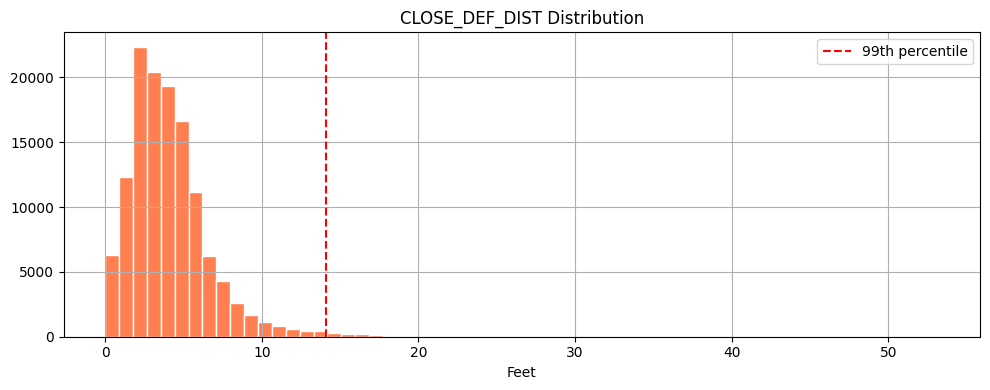


Decision: CLOSE_DEF_DIST left as-is — extreme values are physically valid.


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
NBA_shot_log['CLOSE_DEF_DIST'].hist(bins=60, ax=ax, color='coral', edgecolor='white')
ax.axvline(NBA_shot_log['CLOSE_DEF_DIST'].quantile(0.99), color='red',linestyle='--', label='99th percentile')
ax.set_title('CLOSE_DEF_DIST Distribution')
ax.set_xlabel('Feet')
ax.legend()
plt.tight_layout()
plt.show()
print("\nDecision: CLOSE_DEF_DIST left as-is — extreme values are physically valid.")

# **Derived features**


---

 - Extract Useful Info from MATCHUP & Drop It
 - Flag overtime periods
 - Shot Zone Group & Defender Pressure Level


---



# **Extract Useful Info from MATCHUP & Drop It**


---

**MATCHUP format:** 'MAR 04, 2015 - CHA @ BKN' This is a raw string with 3 pieces of information:
 1. **Date**       → useful (seasonal trends, fatigue across game schedule)
 2. **Team codes** → we already have player_id to identify teams indirectly
 3. **'@' symbol** → home/away, but we already encoded this in LOCATION


---
**Strategy:** extract the **DATE (the most useful signal)**, drop the rest. The team codes and home/away are already captured in other columns.


In [ ]:
print("MATCHUP sample:")
print(NBA_shot_log['MATCHUP'].head(3).tolist())

MATCHUP sample:
['MAR 04, 2015 - CHA @ BKN', 'MAR 04, 2015 - CHA @ BKN', 'MAR 04, 2015 - CHA @ BKN']


In [ ]:
#Extract date using regex — pattern: 'MON DD, YYYY'
NBA_shot_log['MATCHUP_DATE'] = pd.to_datetime(NBA_shot_log['MATCHUP'].str.extract(r'([A-Z]+ \d+, \d{4})')[0],format='%b %d, %Y')

In [ ]:
#Drop the raw string column
NBA_shot_log = NBA_shot_log.drop('MATCHUP', axis=1)

In [ ]:
print("\nMATCHUP replaced by MATCHUP_DATE (datetime)")
print("Date range:", NBA_shot_log['MATCHUP_DATE'].min(), "→", NBA_shot_log['MATCHUP_DATE'].max())


MATCHUP replaced by MATCHUP_DATE (datetime)
Date range: 2014-10-28 00:00:00 → 2015-03-04 00:00:00


## **Flag overtime periods**


---

**PERIOD** values found in the data: [1, 2, 3, 4, 5, 6, 7]
 - Periods 1-4 = regulation quarters
 - Periods 5+ = overtime periods


---
**WHY add a separate IS_OVERTIME binary flag?** overtime shots have a fundamentally different context:
 - Higher game pressure (sudden-death mentality)
 - Player fatigue is extreme (40+ minutes played)
 - Coaching strategy shifts (star players play more minutes)

**A binary flag explicitly teaches the model this discontinuity**


---



In [ ]:
print("PERIOD value counts:")
print(NBA_shot_log['PERIOD'].value_counts().sort_index())

NBA_shot_log['IS_OVERTIME'] = (NBA_shot_log['PERIOD'] > 4).astype(int)

ot_shots = NBA_shot_log['IS_OVERTIME'].sum()
print(f"\nIS_OVERTIME created: {ot_shots:,} overtime shots ({ot_shots/len(NBA_shot_log)*100:.2f}%)")

PERIOD value counts:
PERIOD
1    33961
2    31651
3    32211
4    29123
5      912
6      168
7       43
Name: count, dtype: int64

IS_OVERTIME created: 1,123 overtime shots (0.88%)


# **Derived Feature 1: Shot Zone Group**


---

 - **Close:**       < 8 ft  → high percentage shots (layups, dunks)
 - **Mid-Range:**   8–22 ft → lower efficiency shots
 - **Three-Point:** > 22 ft → 3-point territory


---



In [ ]:
def shot_zone_group(dist):
    if dist < 8:
        return 'Close'
    elif dist <= 22:
        return 'Mid-Range'
    else:
        return 'Three-Point'

NBA_shot_log['SHOT_ZONE_GROUP'] = NBA_shot_log['SHOT_DIST'].apply(shot_zone_group)

print("SHOT_ZONE_GROUP distribution:")
print(NBA_shot_log['SHOT_ZONE_GROUP'].value_counts())
#apply Encoding
encoded = LabelEncoder()
NBA_shot_log['SHOT_GROUP_Encoded'] = encoded.fit_transform(NBA_shot_log['SHOT_ZONE_GROUP'])


SHOT_ZONE_GROUP distribution:
SHOT_ZONE_GROUP
Close          49619
Mid-Range      43460
Three-Point    34990
Name: count, dtype: int64


In [ ]:
NBA_shot_log['SHOT_GROUP_Encoded']

,SHOT_GROUP_Encoded
0,0
1,2
2,1
3,1
4,0
...,...
128064,1
128065,0
128066,1
128067,1


# **Derived Feature 2: Defender Pressure Level**


---

 - **Tight:**     < 2 ft  → heavily contested shot
 - **Contested:** 2–4 ft  → moderately defended
 - **Open:**      > 4 ft  → shooter has space


---

In [ ]:
def defender_pressure(dist):
    if dist < 2:
        return 'Tight'
    elif dist <= 4:
        return 'Contested'
    else:
        return 'Open'

NBA_shot_log['DEFENDER_PRESSURE'] = NBA_shot_log['CLOSE_DEF_DIST'].apply(defender_pressure)

print("DEFENDER_PRESSURE distribution:")
print(NBA_shot_log['DEFENDER_PRESSURE'].value_counts())
print()

# Quick insight: shot success rate by pressure level
print("FGM rate by pressure level:")
print(NBA_shot_log.groupby('DEFENDER_PRESSURE')['FGM'].mean().round(3))

DEFENDER_PRESSURE distribution:
DEFENDER_PRESSURE
Open         55925
Contested    48676
Tight        23468
Name: count, dtype: int64

FGM rate by pressure level:
DEFENDER_PRESSURE
Contested    0.469
Open         0.437
Tight        0.453
Name: FGM, dtype: float64


# **Data After Cleaning:**

In [ ]:
NBA_shot_log

,GAME_ID,LOCATION,W,FINAL_MARGIN,SHOT_NUMBER,PERIOD,SHOT_CLOCK,DRIBBLES,TOUCH_TIME,SHOT_DIST,...,FGM,PTS,player_name,player_id,GAME_CLOCK_SEC,MATCHUP_DATE,IS_OVERTIME,SHOT_ZONE_GROUP,SHOT_GROUP_Encoded,DEFENDER_PRESSURE
0,21400899,0,1,24,1,1,10.8,2,1.9,7.7,...,1,2,brian roberts,203148,69,2015-03-04,0,Close,0,Tight
1,21400899,0,1,24,2,1,3.4,0,0.8,28.2,...,0,0,brian roberts,203148,14,2015-03-04,0,Three-Point,2,Open
2,21400899,0,1,24,3,1,-1.0,3,2.7,10.1,...,0,0,brian roberts,203148,0,2015-03-04,0,Mid-Range,1,Tight
3,21400899,0,1,24,4,2,10.3,2,1.9,17.2,...,0,0,brian roberts,203148,707,2015-03-04,0,Mid-Range,1,Contested
4,21400899,0,1,24,5,2,10.9,2,2.7,3.7,...,0,0,brian roberts,203148,634,2015-03-04,0,Close,0,Tight
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128064,21400006,0,0,-16,5,3,18.3,5,6.2,8.7,...,0,0,jarrett jack,101127,112,2014-10-29,0,Mid-Range,1,Tight
128065,21400006,0,0,-16,6,4,19.8,4,5.2,0.6,...,1,2,jarrett jack,101127,688,2014-10-29,0,Close,0,Tight
128066,21400006,0,0,-16,7,4,23.0,2,4.2,16.9,...,1,2,jarrett jack,101127,670,2014-10-29,0,Mid-Range,1,Open
128067,21400006,0,0,-16,8,4,9.1,4,4.5,18.3,...,0,0,jarrett jack,101127,157,2014-10-29,0,Mid-Range,1,Contested


# **Step 4 — Data Analysis (Exploratory Data Analysis)**


---


# **Overall Shooting Accuracy**:
---

What % of ALL shots were made?

FGM = 1 (made) vs 0 (missed) — baseline success rate

---

 **Shots per Period Distribution:**  (When shot_per_period = NBA_shot_log['PERIOD'])
 **WHAT:** Counts shots taken in each quarter (1-4, plus overtime)
 **WHY:** Teams might shoot differently early vs late (fatigue, strategy)
 **KEY INSIGHT:** Most data in Q1-Q4, overtime rare but important
 **sort_index():** Orders quarters chronologically (1→2→3→4), not alphabetical

---

 **Overall Shooting Accuracy:**  (when shot_outcome_pct = NBA_shot_log['FGM'])
 **WHAT:** % of ALL shots made across entire dataset
 **FGM breakdown:** 1 = made, 0 = missed
 **KEY INSIGHT:** Establishes baseline (~45% typical NBA shooting %)
 **WHY normalize=True:** Gives percentages instead of raw counts

In [ ]:
shot_per_period = NBA_shot_log['PERIOD'].value_counts().sort_index()
print(shot_per_period)

shot_outcome_pct = NBA_shot_log['FGM'].value_counts(normalize=True) * 100
print(shot_outcome_pct)

PERIOD
1    33961
2    31651
3    32211
4    29123
5      912
6      168
7       43
Name: count, dtype: int64
FGM
0    54.786092
1    45.213908
Name: proportion, dtype: float64


# **Court Zone Analysis**:
---
WHY group by distance? Players have different skills by range (Steph = 3s, Shaq = paint)

8ft & 22ft cutoffs = standard NBA zones (restricted area, 3pt line)

---

 **WHAT:** Groups shots into 3 zones by distance:

**.Close (<8 ft)** = paint/dunks
**.Mid-Range (8-22 ft)** = jumpers/post
**.Three-Point (>22 ft)** = beyond arc

**WHY 8ft/22ft cutoffs:** Standard NBA zones (restricted area, 3pt line)

**KEY INSIGHT:** Reveals player tendencies (bigs = close, guards = 3s)



In [ ]:
def get_zone_group(dist):
    if dist < 8: return 'Close (<8 ft)'
    elif dist <= 22: return 'Mid-Range (8-22 ft)'
    else: return 'Three-Point (>22 ft)'

NBA_shot_log['SHOT_ZONE_GROUP'] = NBA_shot_log['SHOT_DIST'].apply(get_zone_group)
zone_accuracy = NBA_shot_log.groupby('SHOT_ZONE_GROUP')['FGM'].mean() * 100
print(zone_accuracy)

SHOT_ZONE_GROUP
Close (<8 ft)           56.637578
Mid-Range (8-22 ft)     40.303728
Three-Point (>22 ft)    35.112889
Name: FGM, dtype: float64


# **Shot Distance Distribution**:
---
Visualize where shots typically happen

KDE curve smooths histogram to show true density

---

 **WHAT:** Histogram + smooth KDE curve of all shot distances

**35 bins:** Good balance of detail vs smoothness

**KEY INSIGHT:** Bimodal distribution? (paint + 3pt peaks)

**BLUE color:** Standard for distance metrics



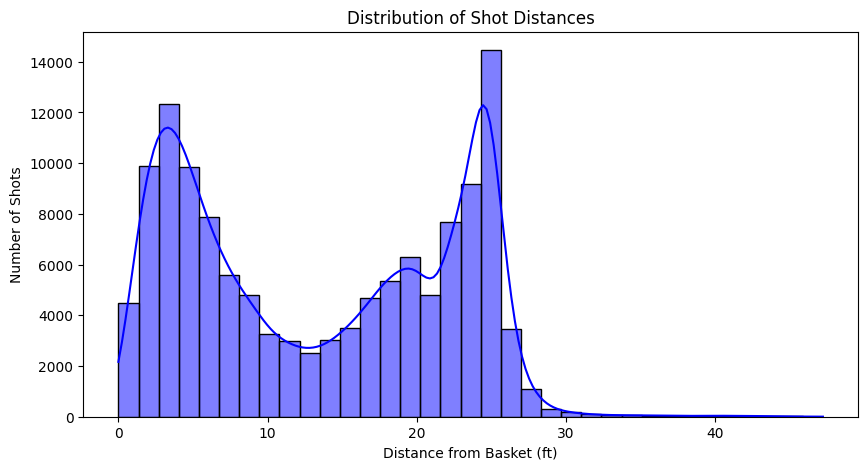

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(NBA_shot_log['SHOT_DIST'], bins=35, kde=True, color='blue')
plt.title('Distribution of Shot Distances')
plt.xlabel('Distance from Basket (ft)')
plt.ylabel('Number of Shots')
plt.show()

# **Defender Distance Impact**:
---
Do closer defenders = more misses?


Boxplot shows: Made shots have defenders farther away

---


 **WHAT:** Boxplot comparing defender distance for made vs missed shots

**KEY INSIGHT:** Made shots = defenders farther away (space matters!)

**Mean print:** Quantifies the gap (~2-3ft difference typical)

**WHY boxplot:** Shows median + spread + outliers



/tmp/ipykernel_13663/2324852586.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='FGM', y='CLOSE_DEF_DIST', data=NBA_shot_log, palette='Set2')


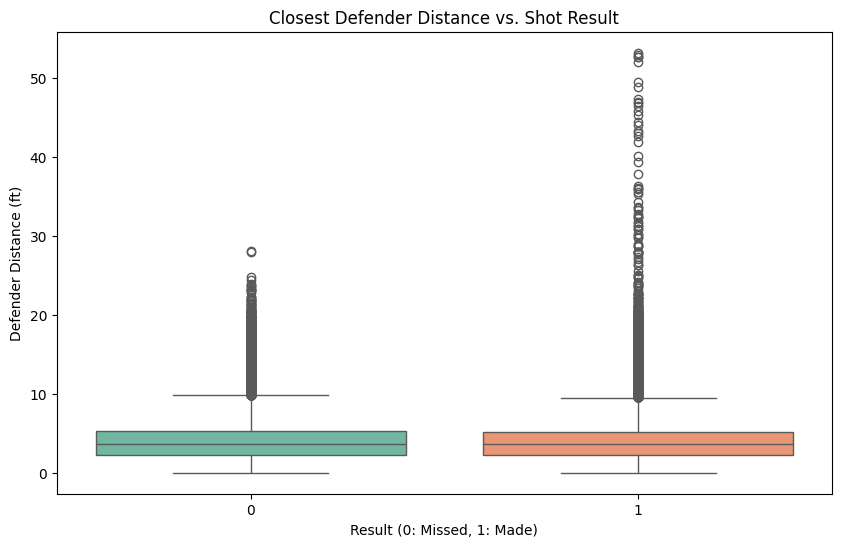

FGM
0    4.125705
1    4.119755
Name: CLOSE_DEF_DIST, dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='FGM', y='CLOSE_DEF_DIST', data=NBA_shot_log, palette='Set2')
plt.title('Closest Defender Distance vs. Shot Result')
plt.xlabel('Result (0: Missed, 1: Made)')
plt.ylabel('Defender Distance (ft)')
plt.show()

print(NBA_shot_log.groupby('FGM')['CLOSE_DEF_DIST'].mean())

# **Dribble Impact**:
---
Do more dribbles = harder shot?

ci=None removes confidence intervals (we want point estimates)

---

 **WHAT:** Average dribbles before made vs missed shots

**ci=None:** Removes confidence intervals (focus on point estimates)

**KEY INSIGHT:** Catch-and-shoot (0 dribbles) > dribble-heavy shots

**VIRIDIS palette:** Professional sequential colors



/tmp/ipykernel_13663/3895388864.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='FGM', y='DRIBBLES', data=NBA_shot_log, ci=None, palette='viridis')
/tmp/ipykernel_13663/3895388864.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='FGM', y='DRIBBLES', data=NBA_shot_log, ci=None, palette='viridis')


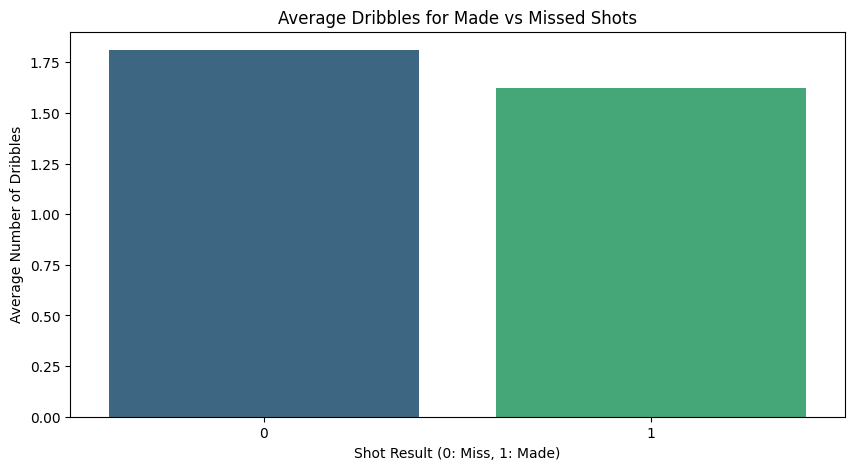

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x='FGM', y='DRIBBLES', data=NBA_shot_log, ci=None, palette='viridis')
plt.title('Average Dribbles for Made vs Missed Shots')
plt.xlabel('Shot Result (0: Miss, 1: Made)')
plt.ylabel('Average Number of Dribbles')
plt.show()

# **Overall Made/Miss Pie Chart**:
---
Quick visual baseline

---

 **WHAT:** Simple proportion of made (green) vs missed (coral) shots

**startangle=90:** Pie starts at top (more intuitive)

**KEY INSIGHT:** Visual baseline before diving deeper



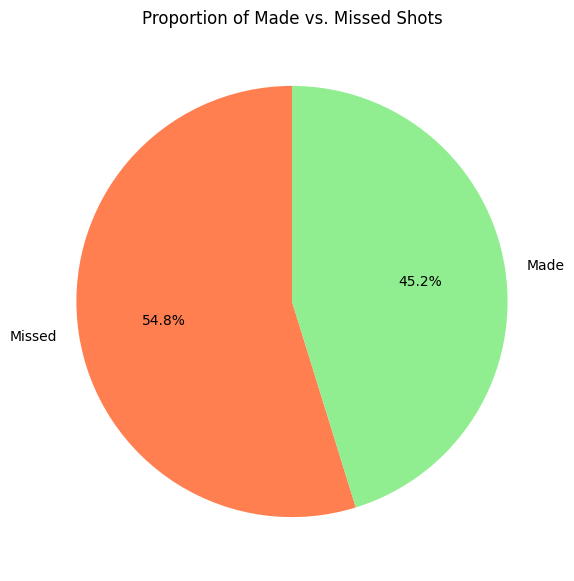

In [ ]:
plt.figure(figsize=(7, 7))
NBA_shot_log['FGM'].value_counts().plot.pie(autopct='%1.1f%%', colors=['coral', 'lightgreen'], labels=['Missed', 'Made'], startangle=90)
plt.title('Proportion of Made vs. Missed Shots')
plt.ylabel('')
plt.show()

# **Zone Shooting % (Horizontal Bar)**:
---
Which zone is easiest/hardest?

sort_values() = worst-to-best (easier to read)

---
 **WHAT:** Success rate by zone, sorted worst→best

**barh:** Horizontal = better zone name readability

**KEY INSIGHT:** Close > 3pt > Mid-range (typical NBA pattern)

**sort_values():** Worst first = natural reading order



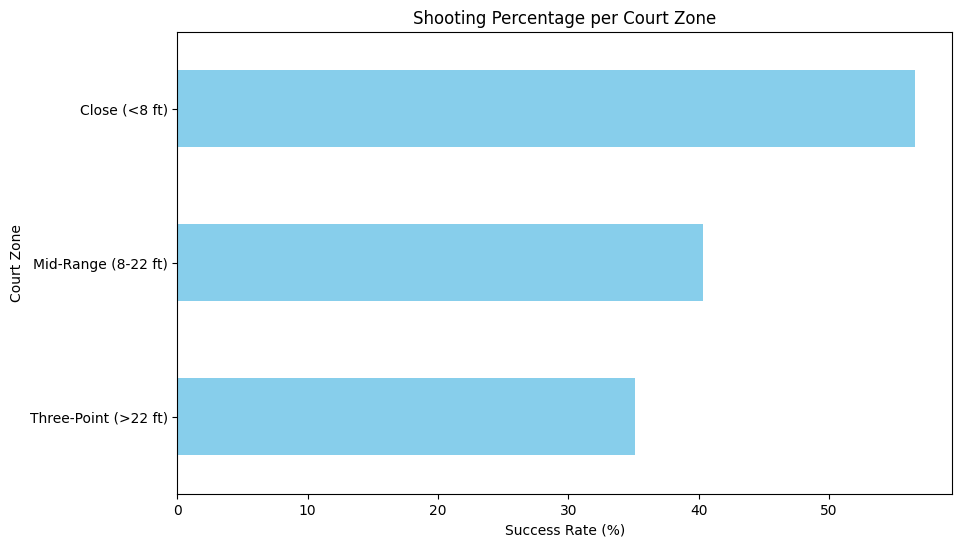

In [ ]:
zone_accuracy = NBA_shot_log.groupby('SHOT_ZONE_GROUP')['FGM'].mean().sort_values() * 100
plt.figure(figsize=(10, 6))
zone_accuracy.plot(kind='barh', color='skyblue')
plt.title('Shooting Percentage per Court Zone')
plt.xlabel('Success Rate (%)')
plt.ylabel('Court Zone')
plt.show()

# **Team Analysis**:
---
LOCATION = 0 (Away) vs 1 (Home) — home court advantage?

---

 **WHAT:** Shots + accuracy by LOCATION (0=Away, 1=Home)

**KEY INSIGHT:** Home court advantage? (~2-3% boost typical)

**groupby(LOCATION).count():** Total shots per team type



In [ ]:
team_shots = NBA_shot_log['LOCATION'].groupby(NBA_shot_log['LOCATION']).count()
print(team_shots)

team_accuracy = NBA_shot_log.groupby('LOCATION')['FGM'].mean() * 100
print(team_accuracy)

LOCATION
0    64135
1    63934
Name: LOCATION, dtype: int64
LOCATION
0    44.811725
1    45.617355
Name: FGM, dtype: float64


# **Top 10 Players (500+ shots)**:
---
Most accurate shooters with meaningful sample size

500+ shots filter = statistical significance

---
 **WHAT:** Most accurate shooters with statistical significance

**500+ shot filter:** Eliminates small-sample noise

**KEY INSIGHT:** Identifies elite shooters for further study

In [ ]:
player_stats = NBA_shot_log.groupby('player_name').agg({'FGM': ['mean', 'count']})
player_stats.columns = ['accuracy', 'count']
top_players = player_stats[player_stats['count'] > 500].sort_values(by='accuracy', ascending=False).head(10)
print(top_players['accuracy'] * 100)

player_name
marcin gortat         54.561404
derrick favors        54.505170
anthony davis         54.340071
al horford            54.125874
nikola vucevic        53.215078
carlos boozer         51.451613
donatas motiejunas    50.868056
andre drummond        50.827068
goran dragic          50.199203
blake griffin         50.055991
Name: accuracy, dtype: float64


# **Shot Clock Timing**:
---
Are shots better with more/less time remaining?

common_norm=False = separate density scales for made/miss

---
 **WHAT:** Density plots of shot clock for made vs missed

**common_norm=False:** Separate scales (made shots rarer)

**KEY INSIGHT:** End-of-clock heaves worse? Early shots better?

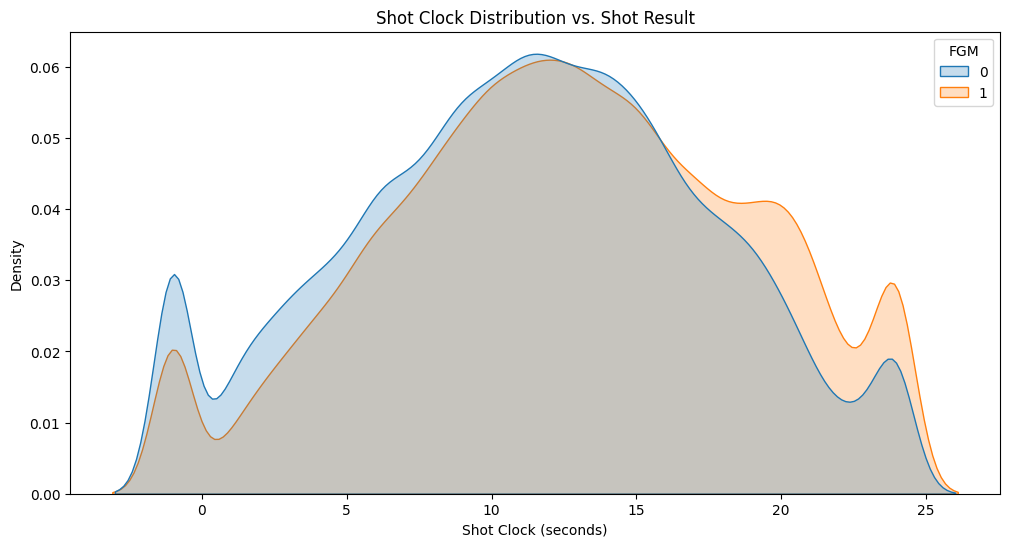

In [ ]:
plt.figure(figsize=(12, 6))
sns.kdeplot(data=NBA_shot_log, x='SHOT_CLOCK', hue='FGM', fill=True, common_norm=False)
plt.title('Shot Clock Distribution vs. Shot Result')
plt.xlabel('Shot Clock (seconds)')
plt.ylabel('Density')
plt.show()

# **Period-by-Period Accuracy**:
---
Do teams get tired?

---
 **WHAT:** Line plot of shooting % across quarters

**marker='o':** Emphasizes each period

**KEY INSIGHT:** Fatigue effect? Clutch time drop-off?

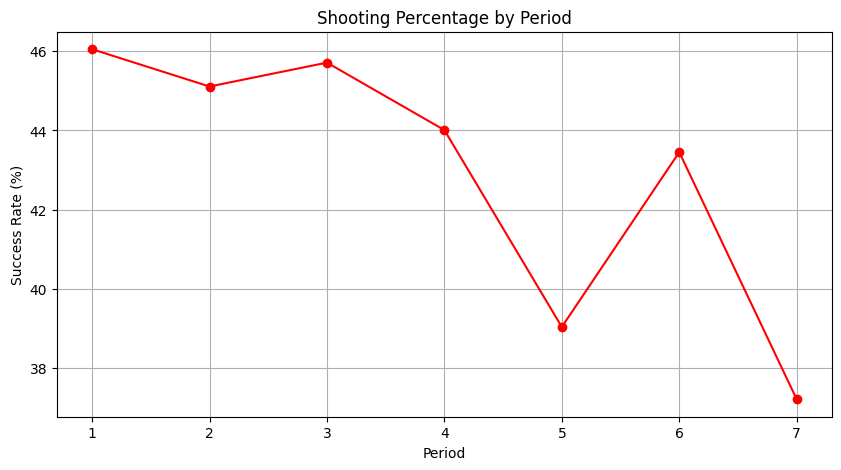

In [ ]:
period_accuracy = NBA_shot_log.groupby('PERIOD')['FGM'].mean() * 100
plt.figure(figsize=(10, 5))
period_accuracy.plot(kind='line', marker='o', color='red')
plt.title('Shooting Percentage by Period')
plt.xlabel('Period')
plt.ylabel('Success Rate (%)')
plt.grid(True)
plt.show()

# **Defender Pressure Levels**:
---
Quantify "contested" vs "open"

2ft/4ft cutoffs = NBA tracking standard

---
 **WHAT:** 3 pressure categories by defender distance:

**. Tight (<2ft)** = hands in face
**.Contested (2-4ft)** = close but not touching
**.Open (>4ft)** = space

**2ft/4ft cutoffs:** NBA tracking standards

**KEY INSIGHT:** Open >> Contested >> Tight (as expected)

In [ ]:
def get_pressure_level(dist):
    if dist < 2: return 'Tight (< 2 ft)'
    elif dist <= 4: return 'Contested (2-4 ft)'
    else: return 'Open (> 4 ft)'

NBA_shot_log['DEFENDER_PRESSURE'] = NBA_shot_log['CLOSE_DEF_DIST'].apply(get_pressure_level)
pressure_accuracy = NBA_shot_log.groupby('DEFENDER_PRESSURE')['FGM'].mean() * 100
print(pressure_accuracy)

DEFENDER_PRESSURE
Contested (2-4 ft)    46.879366
Open (> 4 ft)         43.740724
Tight (< 2 ft)        45.270155
Name: FGM, dtype: float64


/tmp/ipykernel_13663/3733952303.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pressure_accuracy.index, y=pressure_accuracy.values, palette='magma')


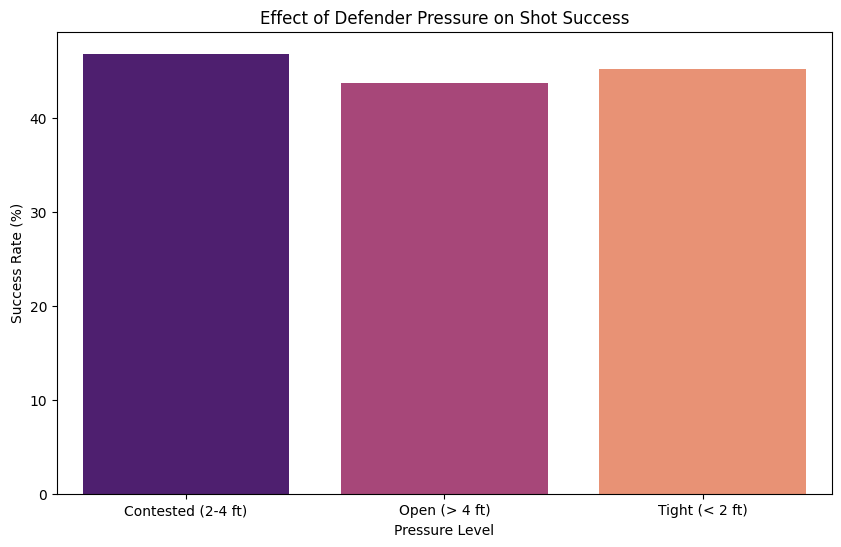

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x=pressure_accuracy.index, y=pressure_accuracy.values, palette='magma')
plt.title('Effect of Defender Pressure on Shot Success')
plt.xlabel('Pressure Level')
plt.ylabel('Success Rate (%)')
plt.show()

# **Distance vs Defender Scatter**:
---
Do long shots = more space?

sample(1000) = plot performance

---
 **WHAT:** 1000-shot sample: shot distance vs defender distance

**sample(1000):** Plot performance (full dataset = millions points)

**KEY INSIGHT:** Long shots = more space? Corner 3s pattern?

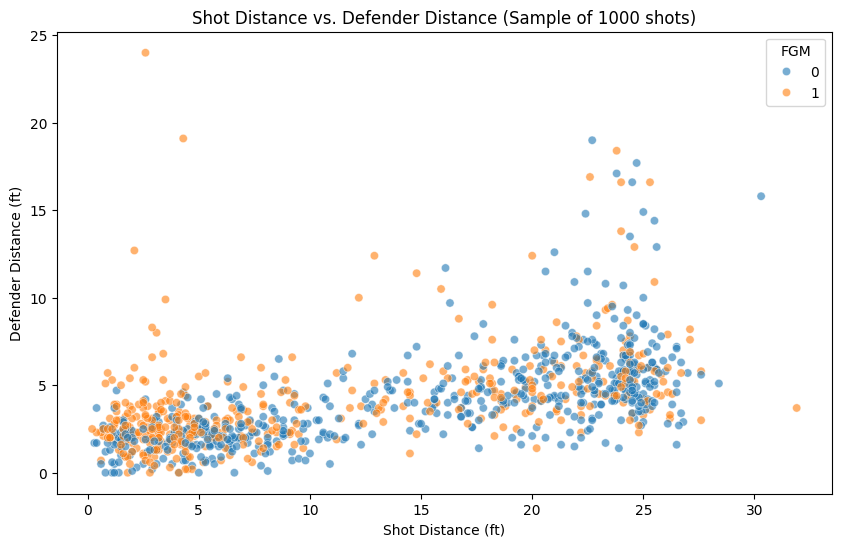

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=NBA_shot_log.sample(1000), x='SHOT_DIST', y='CLOSE_DEF_DIST', hue='FGM', alpha=0.6)
plt.title('Shot Distance vs. Defender Distance (Sample of 1000 shots)')
plt.xlabel('Shot Distance (ft)')
plt.ylabel('Defender Distance (ft)')
plt.show()

# **Feature Summary Statistics**:
---
Quick ranges/checks before modeling

---
**WHAT**: describe() on key numeric features

**KEY INSIGHT:** Ranges, means, std devs → spot issues before modeling

**Includes:** Distance, defender, clock, dribbles, touch time

In [ ]:
print(NBA_shot_log[['SHOT_DIST', 'CLOSE_DEF_DIST', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME']].describe())

           SHOT_DIST  CLOSE_DEF_DIST     SHOT_CLOCK       DRIBBLES  \
count  128069.000000   128069.000000  128069.000000  128069.000000   
mean       13.571504        4.123015      11.868544       1.727014   
std         8.888964        2.756446       6.268730       2.467408   
min         0.000000        0.000000      -1.000000       0.000000   
25%         4.700000        2.300000       7.500000       0.000000   
50%        13.700000        3.700000      12.000000       1.000000   
75%        22.500000        5.300000      16.400000       2.000000   
max        47.200000       53.200000      24.000000       8.000000   

          TOUCH_TIME  
count  128069.000000  
mean        2.550809  
std         2.246596  
min         0.000000  
25%         0.900000  
50%         1.600000  
75%         3.700000  
max         7.900000  


# **2PT vs 3PT Success**:
---
PTS_TYPE = 2 (twos) vs 3 (threes)

---
**WHAT:** Raw success rates (not points per shot)

**PTS_TYPE:** 2 = twos, 3 = threes

**KEY INSIGHT:** 2s ~50%, 3s ~35% (but 3s more valuable)

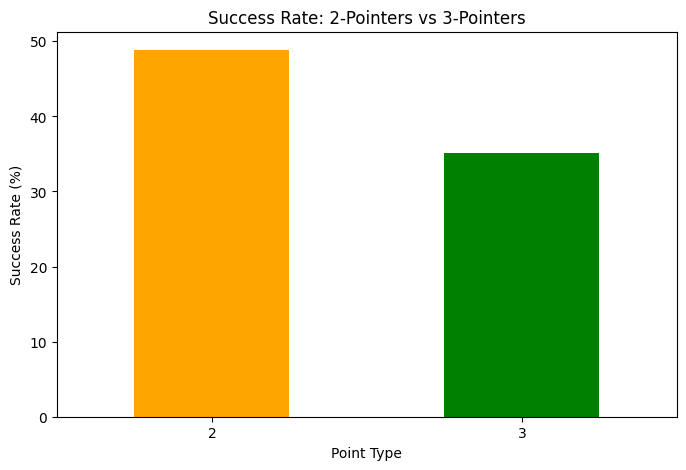

In [ ]:
shot_type_accuracy = NBA_shot_log.groupby('PTS_TYPE')['FGM'].mean() * 100
plt.figure(figsize=(8, 5))
shot_type_accuracy.plot(kind='bar', color=['orange', 'green'])
plt.title('Success Rate: 2-Pointers vs 3-Pointers')
plt.xlabel('Point Type')
plt.ylabel('Success Rate (%)')
plt.xticks(rotation=0)
plt.show()

# **Shots by Game Time**:
---
**WHAT**: Shots per minute remaining in quarter

**GAME_CLOCK_SEC // 60:** Integer minutes

**KEY INSIGHT**: More shots late? Clutch time effect?

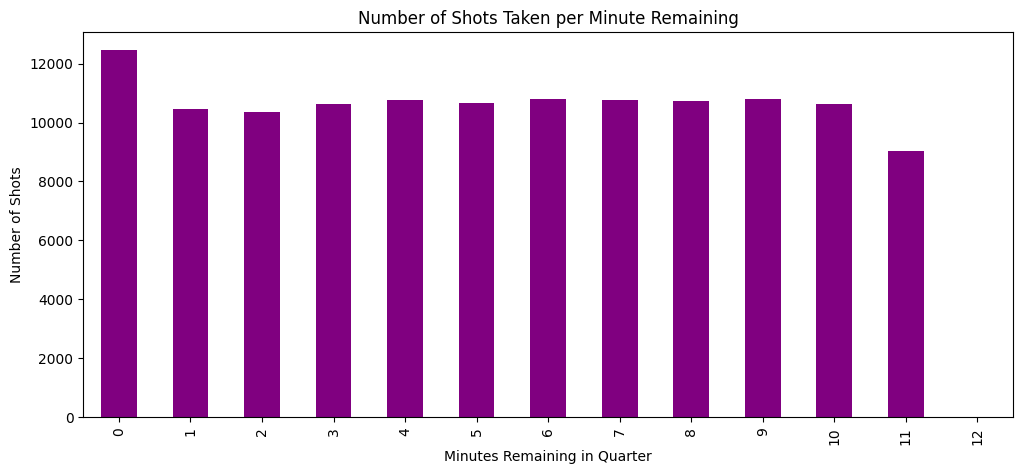

In [ ]:
NBA_shot_log['MINUTES_REMAINING'] = NBA_shot_log['GAME_CLOCK_SEC'] // 60
minutes_dist = NBA_shot_log.groupby('MINUTES_REMAINING')['FGM'].count()
plt.figure(figsize=(12, 5))
minutes_dist.plot(kind='bar', color='purple')
plt.title('Number of Shots Taken per Minute Remaining')
plt.xlabel('Minutes Remaining in Quarter')
plt.ylabel('Number of Shots')
plt.show()

# **Correlation Heatmap**:
---
Which features move together?

Goal: Spot multicollinearity before modeling

----

**WHAT**: Pearson correlations between all key features

**annot**=True, fmt='.2f': Exact values on cells

**coolwarm cmap**: Red=positive, Blue=negative

**KEY INSIGHT:**

Multicollinearity warnings

Unexpected relationships (dribbles vs touch time?)

Target (FGM) correlations = feature importance hints

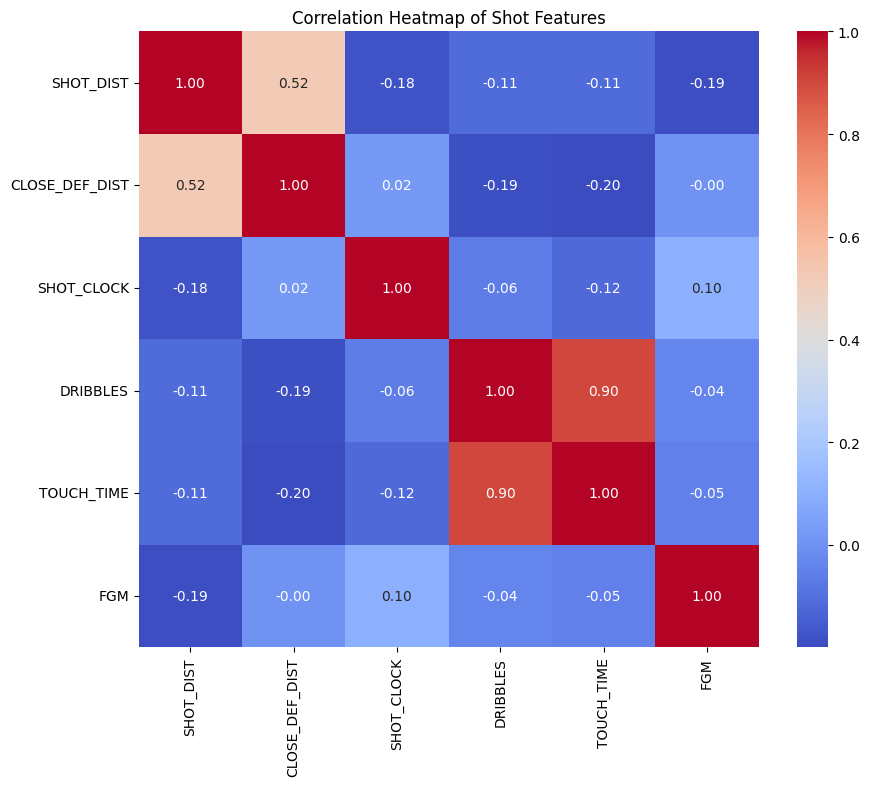

In [ ]:
plt.figure(figsize=(10, 8))
corr_matrix = NBA_shot_log[['SHOT_DIST', 'CLOSE_DEF_DIST', 'SHOT_CLOCK', 'DRIBBLES', 'TOUCH_TIME', 'FGM']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Shot Features')
plt.show()

# **Step 5 — Application of Data Mining Techniques**


---

 - Clustring
 - Classification
 - Association

# **Clustring**

---
*  PLAYER SHOOTING STYLE CLUSTERING
* Goal: Group NBA players by their shooting behavior using K-Means clustering.

* Features used:

  * **avg_shot_dist**      : average distance (ft) of all shot attempts
  * **shooting_percentage**: field goal percentage (shots made / shots taken)
  * **three_point_rate**   : share of attempts that are 3-pointers
  * **paint_attempt_rate** : share of attempts taken inside the paint (<8 ft)



#   **step**(1):-  prepare **features**




In [ ]:
print(f"Dataset: {len(NBA_shot_log):,} shot records | {NBA_shot_log['player_name'].nunique()} unique players")

# These per-shot flags are averaged at the player level to produce rates.

# Paint shot: any attempt taken within 8 feet of the basket
NBA_shot_log['is_paint_shot'] = (NBA_shot_log['SHOT_DIST'] < 8).astype(int)

# Three-point attempt: identified by the PTS_TYPE column (2 = mid/paint, 3 = three)
NBA_shot_log['is_three_shot'] = (NBA_shot_log['PTS_TYPE'] == 3).astype(int)

player_features = NBA_shot_log.groupby('player_name').agg(
    avg_shot_dist      = ('SHOT_DIST',     'mean'),   # average shot distance
    shooting_percentage= ('FGM',           'mean'),   # FG% (FGM is 0/1 per shot)
    three_point_rate   = ('is_three_shot', 'mean'),   # 3PA / total attempts
    paint_attempt_rate = ('is_paint_shot', 'mean'),   # paint shots / total attempts
    total_shots        = ('SHOT_DIST',     'count'),  # total attempts (for filtering)
).reset_index()

# Remove players with fewer than 50 shot attempts — small samples produce
# unstable feature estimates and distort cluster centroids.
player_features = player_features[player_features['total_shots'] >= 50].reset_index(drop=True)

print(f"Players after min-shot filter (≥50 attempts): {len(player_features)}")
display(player_features.head())


Dataset: 128,069 shot records | 281 unique players
Players after min-shot filter (≥50 attempts): 280


,player_name,avg_shot_dist,shooting_percentage,three_point_rate,paint_attempt_rate,total_shots
0,aaron brooks,15.088592,0.415330,0.388592,0.358289,561
1,aaron gordon,10.062500,0.528846,0.192308,0.576923,104
2,al farouq aminu,12.893411,0.430233,0.368217,0.496124,258
3,al horford,11.973566,0.541259,0.040559,0.437762,715
4,al jefferson,9.315375,0.477500,0.003750,0.465000,800


# **step**(2):- Scale features (required for **distance**-based clustering)


In [ ]:
# K-Means minimises Euclidean distance, so features on larger scales
# (e.g. avg_shot_dist in feet) would dominate over rates (0–1).
# StandardScaler transforms each feature to mean=0, std=1.

features = ['avg_shot_dist', 'shooting_percentage', 'three_point_rate', 'paint_attempt_rate']

scaler      = StandardScaler()
data_scaled = scaler.fit_transform(player_features[features])

# **step(3)**:- Use the **Elbow Method** to choose the optimal number of clusters

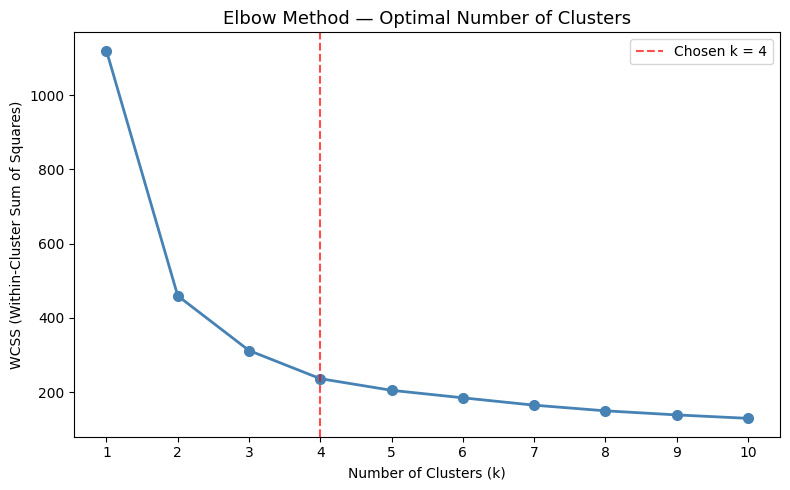

In [ ]:
# WCSS (Within-Cluster Sum of Squares) measures how tightly packed each
# cluster is. We plot WCSS for k = 1 … 10 and look for the "elbow" — the
# point where adding more clusters gives diminishing returns.

wcss = []
K_RANGE = range(1, 11)

for k in K_RANGE:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_temp.fit(data_scaled)
    wcss.append(km_temp.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), wcss, marker='o', color='steelblue', linewidth=2, markersize=7)
plt.axvline(x=4, color='red', linestyle='--', alpha=0.7, label='Chosen k = 4')
plt.title('Elbow Method — Optimal Number of Clusters', fontsize=13)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(K_RANGE))
plt.legend()
plt.tight_layout()
plt.show()

# The curve bends most noticeably at k = 4; after that the improvement
# per additional cluster is small — confirming k = 4 as our optimal choice

# **step**(4):- Fit K-Means model

In [ ]:
K_OPTIMAL = 4

km_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
km_final.fit(data_scaled)

player_features['cluster'] = km_final.labels_

# Print the raw cluster centroids (in scaled space) for inspection
print("\nCluster centroids (scaled):")
centers_df = pd.DataFrame(km_final.cluster_centers_, columns=features)
print(centers_df.round(3))


Cluster centroids (scaled):
   avg_shot_dist  shooting_percentage  three_point_rate  paint_attempt_rate
0          1.068               -0.767             1.145              -0.931
1         -0.985                0.587            -1.094               0.822
2         -1.869                2.046            -1.227               2.061
3          0.140               -0.196            -0.010              -0.203


# **step(5)**:- Label each cluster with a descriptive shooting archetype



In [ ]:
# We inspect each cluster's mean feature values and assign a descriptive label.
# The mapping is data-driven: we rank clusters by the dominant trait.

cluster_means = player_features.groupby('cluster')[features].mean()
print("\nCluster means (original scale):")
print(cluster_means.round(3))

def assign_archetype_labels(means):
    """
    Automatically assign archetype labels based on cluster feature means.
    Rules (applied in order to avoid double-assignment):
      - Highest paint_attempt_rate  → 'Paint Scorers'
      - Highest three_point_rate    → 'Three-Point Shooters'
      - Lowest  avg_shot_dist (remaining) → 'Mid-Range Specialists'
      - Remaining cluster           → 'Versatile Scorers'
    """
    labels   = {}
    remaining = list(means.index)

    # Paint Scorers: live inside the paint
    idx = means.loc[remaining, 'paint_attempt_rate'].idxmax()
    labels[idx] = 'Paint Scorers'
    remaining.remove(idx)

    # Three-Point Shooters: perimeter-heavy
    idx = means.loc[remaining, 'three_point_rate'].idxmax()
    labels[idx] = 'Three-Point Shooters'
    remaining.remove(idx)

    # Mid-Range Specialists: closest to the basket among the remaining non-paint clusters
    idx = means.loc[remaining, 'avg_shot_dist'].idxmin()
    labels[idx] = 'Mid-Range Specialists'
    remaining.remove(idx)

    # Versatile Scorers: balanced shot distribution
    labels[remaining[0]] = 'Versatile Scorers'

    return labels

archetype_map = assign_archetype_labels(cluster_means)
player_features['archetype'] = player_features['cluster'].map(archetype_map)

print("\n CLUSTER → ARCHETYPE MAPPING ")
for cluster_id, name in sorted(archetype_map.items()):
    print(f"  Cluster {cluster_id} → {name}")


Cluster means (original scale):
         avg_shot_dist  shooting_percentage  three_point_rate  \
cluster                                                         
0               18.209                0.406             0.517   
1                9.063                0.485             0.042   
2                5.123                0.571             0.014   
3               14.076                0.439             0.272   

         paint_attempt_rate  
cluster                      
0                     0.201  
1                     0.576  
2                     0.841  
3                     0.357  

 CLUSTER → ARCHETYPE MAPPING 
  Cluster 0 → Three-Point Shooters
  Cluster 1 → Mid-Range Specialists
  Cluster 2 → Paint Scorers
  Cluster 3 → Versatile Scorers


# **summary table**

In [ ]:
summary = (
    player_features.groupby('archetype').agg(
        num_players        = ('player_name',       'count'),
        avg_shot_dist      = ('avg_shot_dist',      'mean'),
        shooting_pct       = ('shooting_percentage','mean'),
        three_point_rate   = ('three_point_rate',   'mean'),
        paint_attempt_rate = ('paint_attempt_rate', 'mean'),
    )
    .round(3)
    .sort_values('avg_shot_dist', ascending=False)
)

print("\n CLUSTER SUMMARY ")
display(summary)


 CLUSTER SUMMARY 


,num_players,avg_shot_dist,shooting_pct,three_point_rate,paint_attempt_rate
archetype,,,,,
Three-Point Shooters,87,18.209,0.406,0.517,0.201
Versatile Scorers,106,14.076,0.439,0.272,0.357
Mid-Range Specialists,62,9.063,0.485,0.042,0.576
Paint Scorers,25,5.123,0.571,0.014,0.841


# **top players per cluster**

In [ ]:
print("\n TOP 5 PLAYERS PER CLUSTER (by shot volume) ")
for archetype, grp in player_features.groupby('archetype'):
    top5 = grp.nlargest(5, 'total_shots')['player_name'].str.title().tolist()
    print(f"\n{archetype}:")
    for name in top5:
        print(f"  • {name}")


 TOP 5 PLAYERS PER CLUSTER (by shot volume) 

Mid-Range Specialists:
  • Tyreke Evans
  • Nikola Vucevic
  • Blake Griffin
  • Anthony Davis
  • Pau Gasol

Paint Scorers:
  • Greg Monroe
  • Andre Drummond
  • Jonas Valanciunas
  • Timofey Mozgov
  • Tyler Zeller

Three-Point Shooters:
  • Klay Thompson
  • Stephen Curry
  • Jamal Crawford
  • Trey Burke
  • Avery Bradley

Versatile Scorers:
  • James Harden
  • Mnta Ellis
  • Lamarcus Aldridge
  • Damian Lillard
  • Lebron James


# **step**(6):- Visualise the clusters


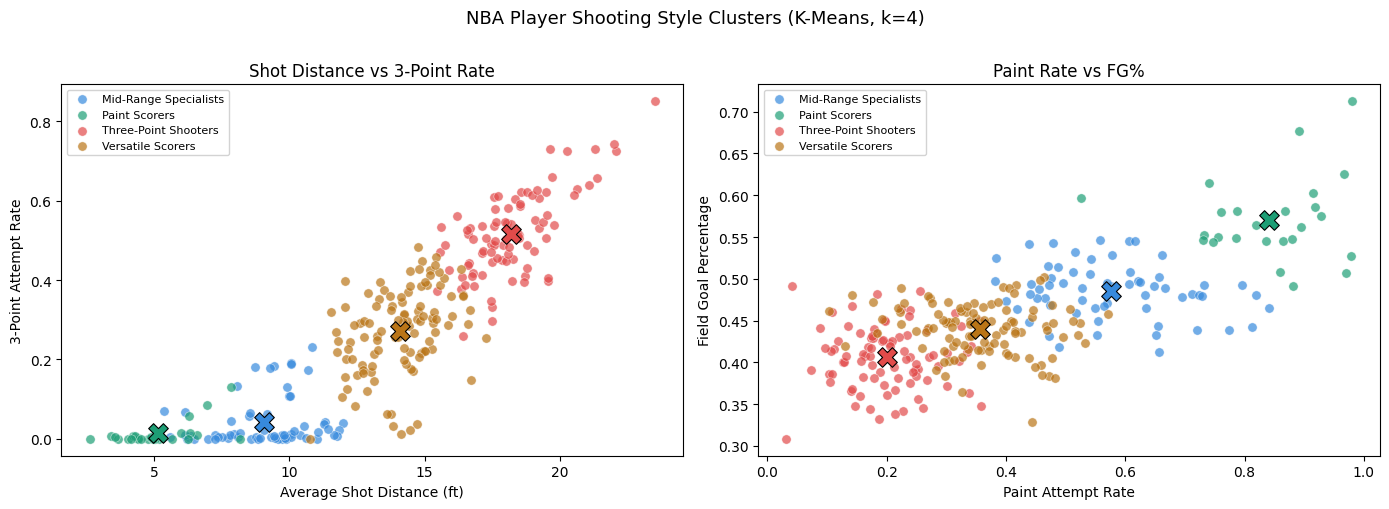

In [ ]:
PALETTE = {
    'Three-Point Shooters':  '#E24B4A',
    'Mid-Range Specialists': '#378ADD',
    'Paint Scorers':         '#1D9E75',
    'Versatile Scorers':     '#BA7517',
}

color_list = player_features['archetype'].map(PALETTE)

# ____ Scatter: Shot Distance vs 3-Point Rate ____
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for archetype, grp in player_features.groupby('archetype'):
    axes[0].scatter(
        grp['avg_shot_dist'], grp['three_point_rate'],
        c=PALETTE[archetype], label=archetype,
        alpha=0.7, s=45, edgecolors='white', linewidths=0.4
    )

# Overlay cluster centroids (inverse-transformed to original scale)
centers_original = scaler.inverse_transform(km_final.cluster_centers_)
feat_idx = {f: i for i, f in enumerate(features)}

for i, center in enumerate(centers_original):
    archetype = archetype_map[i]
    axes[0].scatter(
        center[feat_idx['avg_shot_dist']],
        center[feat_idx['three_point_rate']],
        c=PALETTE[archetype], marker='X', s=200,
        edgecolors='black', linewidths=0.8, zorder=5
    )

axes[0].set_xlabel('Average Shot Distance (ft)')
axes[0].set_ylabel('3-Point Attempt Rate')
axes[0].set_title('Shot Distance vs 3-Point Rate')
axes[0].legend(fontsize=8, framealpha=0.85)

# ____  Scatter: Paint Rate vs FG% ____
for archetype, grp in player_features.groupby('archetype'):
    axes[1].scatter(
        grp['paint_attempt_rate'], grp['shooting_percentage'],
        c=PALETTE[archetype], label=archetype,
        alpha=0.7, s=45, edgecolors='white', linewidths=0.4
    )

for i, center in enumerate(centers_original):
    archetype = archetype_map[i]
    axes[1].scatter(
        center[feat_idx['paint_attempt_rate']],
        center[feat_idx['shooting_percentage']],
        c=PALETTE[archetype], marker='X', s=200,
        edgecolors='black', linewidths=0.8, zorder=5
    )

axes[1].set_xlabel('Paint Attempt Rate')
axes[1].set_ylabel('Field Goal Percentage')
axes[1].set_title('Paint Rate vs FG%')
axes[1].legend(fontsize=8, framealpha=0.85)

plt.suptitle('NBA Player Shooting Style Clusters (K-Means, k=4)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()



# **Classification**


---
Predict Shot Result (**Made or Missed**)

 Goal: Build a model that predicts whether a shot will be made (FGM=1)
       or missed (FGM=0) based on shot and game context features.

-**Target** **variable** : FGM (1 = made, 0 = missed)
-**Features** **used**:
   - **SHOT_DIST**      : distance from basket (ft)
   - **CLOSE_DEF_DIST** : distance of nearest defender (ft)
   - **SHOT_ZONE_GROUP**: zone of the court (paint / mid / perimeter)
   - **PTS_TYPE**       : shot type (2 = two-pointer, 3 = three-pointer)
   - **PERIOD**         : quarter of the game (1–4, plus overtime)



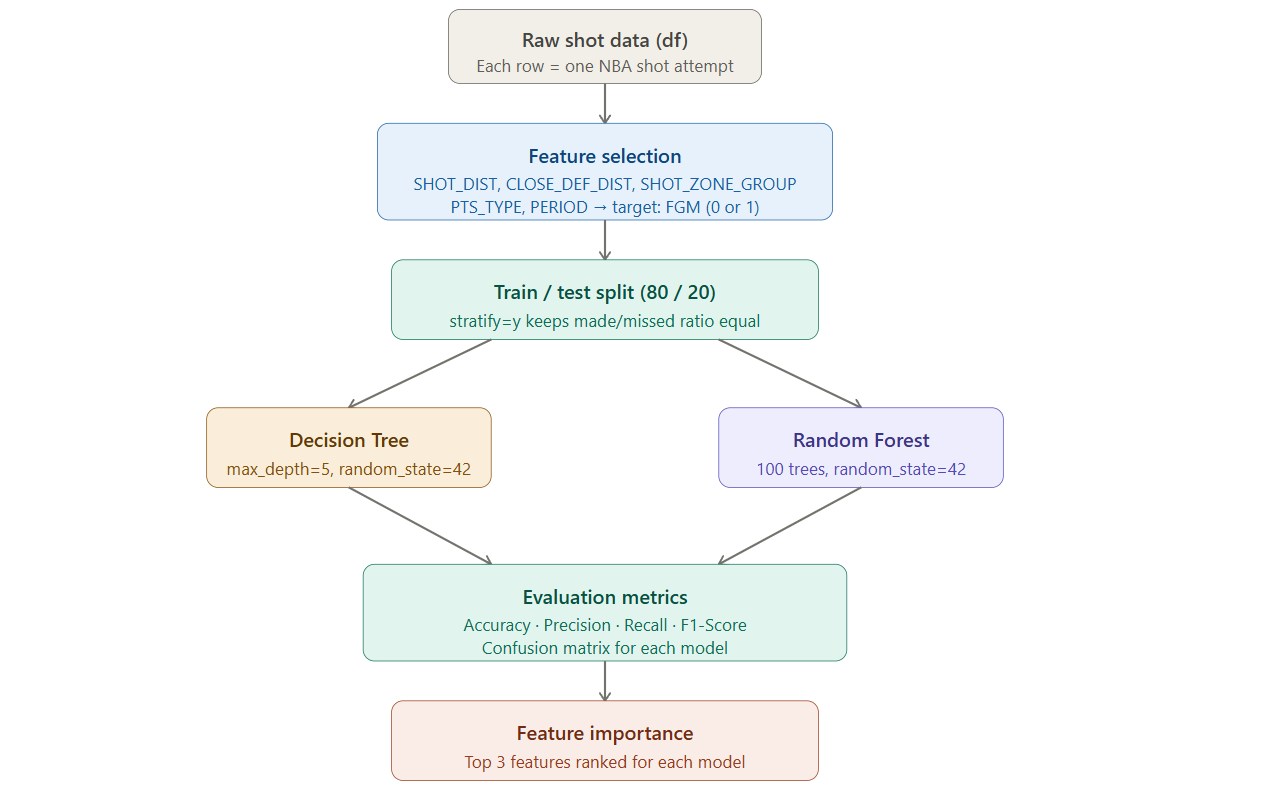

# **1- select features and target**


---



In [ ]:
# These five features are available per shot and directly influence
# whether a shot goes in or not.

FEATURES = ['SHOT_DIST', 'CLOSE_DEF_DIST', 'SHOT_GROUP_Encoded', 'PTS_TYPE', 'PERIOD']
TARGET    = 'FGM'   # 1 = shot made, 0 = shot missed

# Drop rows where any selected feature or the target is missing
model_df = NBA_shot_log[FEATURES + [TARGET]].dropna()

X = model_df[FEATURES]
y = model_df[TARGET]

print(f"Total samples : {len(model_df):,}")
print(f"Shots made    : {y.sum():,} ({y.mean():.1%})")
print(f"Shots missed  : {(1-y).sum():,} ({(1-y.mean()):.1%})")

Total samples : 128,069
Shots made    : 57,905 (45.2%)
Shots missed  : 70,164 (54.8%)


In [ ]:
NBA_shot_log[['SHOT_DIST', 'CLOSE_DEF_DIST', 'SHOT_GROUP_Encoded', 'PTS_TYPE', 'PERIOD']]

,SHOT_DIST,CLOSE_DEF_DIST,SHOT_GROUP_Encoded,PTS_TYPE,PERIOD
0,7.7,1.3,0,2,1
1,28.2,6.1,2,3,1
2,10.1,0.9,1,2,1
3,17.2,3.4,1,2,2
4,3.7,1.1,0,2,2
...,...,...,...,...,...
128064,8.7,0.8,1,2,3
128065,0.6,0.6,0,2,4
128066,16.9,4.2,1,2,4
128067,18.3,3.0,1,2,4


# **2- train / test split**


---



In [ ]:
# We keep 80% of shots for training and 20% for testing.
# random_state=42 ensures reproducible results every run.
# stratify=y keeps the same made/missed ratio in both splits.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTraining set : {len(X_train):,} shots")
print(f"Testing set  : {len(X_test):,} shots")


Training set : 102,455 shots
Testing set  : 25,614 shots


# **3- train decision tree**


---



In [ ]:
# max_depth=5 prevents the tree from memorising the training data (overfitting).
# A deeper tree fits training data perfectly but performs poorly on new shots.

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

# **4- evaluate on test set**


---



In [ ]:
y_pred = dt.predict(X_test)

print("\n MODEL PERFORMANCE : ")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Missed', 'Made']))



 MODEL PERFORMANCE : 
Accuracy : 61.10%

Classification Report:
              precision    recall  f1-score   support

      Missed       0.61      0.83      0.70     14033
        Made       0.63      0.35      0.45     11581

    accuracy                           0.61     25614
   macro avg       0.62      0.59      0.57     25614
weighted avg       0.62      0.61      0.59     25614



# **5-  visualise the tree**


---



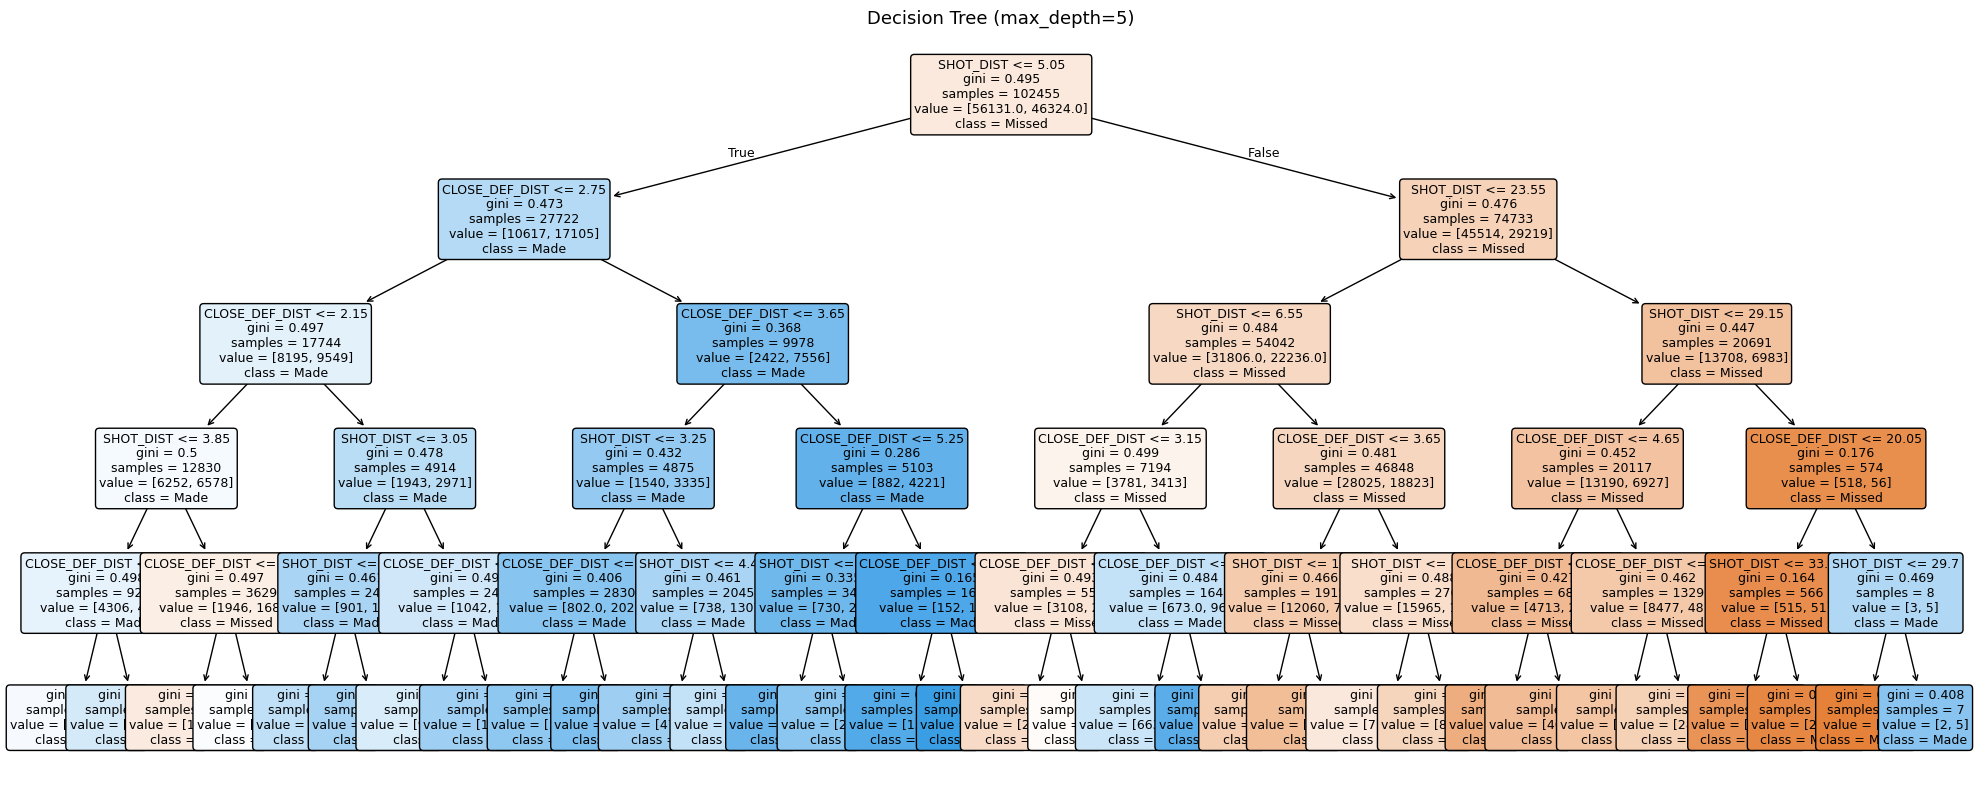

In [ ]:
# Shows the actual decision rules the model learned.
# Each node shows: the splitting feature, the threshold,
# how many samples reach it, and the predicted class.

plt.figure(figsize=(20, 8))
plot_tree(
    dt,
    feature_names=FEATURES,
    class_names=['Missed', 'Made'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree (max_depth=5)', fontsize=13)
plt.tight_layout()
plt.show()

# **Association**


---

── **Build the Transaction Table** ──
 - Apriori/FP-Growth need boolean (True/False) columns.
 - Each column answers one yes/no basketball question per shot.


In [ ]:
assoc_df = pd.DataFrame({

    #WHERE was the shot taken?
    'paint_shot'        : NBA_shot_log['SHOT_DIST'] < 8,
    'midrange_shot'     : NBA_shot_log['SHOT_DIST'].between(8, 22),
    'three_point_shot'  : NBA_shot_log['SHOT_DIST'] > 22,

    #HOW CLOSE was the defender?
    'low_defender_dist'  : NBA_shot_log['CLOSE_DEF_DIST'] < 2,
    'mid_defender_dist'  : NBA_shot_log['CLOSE_DEF_DIST'].between(2, 4),
    'high_defender_dist' : NBA_shot_log['CLOSE_DEF_DIST'] > 4,

    #SHOT TYPE
    'two_pointer'  : NBA_shot_log['PTS_TYPE'] == 2,
    'three_pointer': NBA_shot_log['PTS_TYPE'] == 3,

    #OUTCOME
    'high_shot_success': NBA_shot_log['FGM'] == 1,
    'shot_missed'      : NBA_shot_log['FGM'] == 0,
})

print("Transaction table ready")
print("Shape:", assoc_df.shape)
print(assoc_df.head(3))

Transaction table ready
Shape: (128069, 10)
   paint_shot  midrange_shot  three_point_shot  low_defender_dist  \
0        True          False             False               True   
1       False          False              True              False   
2       False           True             False               True   

   mid_defender_dist  high_defender_dist  two_pointer  three_pointer  \
0              False               False         True          False   
1              False                True        False           True   
2              False               False         True          False   

   high_shot_success  shot_missed  
0               True        False  
1              False         True  
2              False         True  


In [ ]:
#Run APRIORI
#min_support = 0.1 → pattern must appear in at least 10% of all shots

frequent_itemsets_ap = apriori(assoc_df, min_support=0.1, use_colnames=True)

print(f"Apriori — frequent itemsets found: {len(frequent_itemsets_ap)}")

Apriori — frequent itemsets found: 54


In [ ]:
#FP-GROWTH
#Same threshold — results will be identical to Apriori but faster

frequent_itemsets_fp = fpgrowth(assoc_df, min_support=0.1, use_colnames=True)

print(f"FP-Growth — frequent itemsets found: {len(frequent_itemsets_fp)}")

FP-Growth — frequent itemsets found: 54


In [ ]:
# ── Generate Rules from FP-GROWTH ──
rules_fp = association_rules(frequent_itemsets_fp, metric='confidence', min_threshold=0.5)
rules_fp = rules_fp.sort_values('lift', ascending=False)

shot_rules_fp = rules_fp[
    rules_fp['consequents'].apply(
        lambda x: 'high_shot_success' in x or 'shot_missed' in x)
].copy().sort_values('confidence', ascending=False)

print(f"FP-Growth — shot outcome rules found: {len(shot_rules_fp)}")

FP-Growth — shot outcome rules found: 28


In [ ]:
# ── Apriori Results Table ──
ap_table = shot_rules_fp[['antecedents','consequents','support','confidence']].head(10).copy()
ap_table['antecedents'] = ap_table['antecedents'].apply(lambda x: ' + '.join(list(x)))
ap_table['consequents'] = ap_table['consequents'].apply(lambda x: ', '.join(list(x)))
ap_table['support']     = ap_table['support'].round(3)
ap_table['confidence']  = ap_table['confidence'].round(3)

print("=== APRIORI RULES ===")
ap_table

=== APRIORI RULES ===


,antecedents,consequents,support,confidence
22,three_point_shot,shot_missed,0.177,0.649
37,three_point_shot + three_pointer,shot_missed,0.166,0.649
30,three_pointer,shot_missed,0.172,0.648
46,high_defender_dist + three_point_shot + three_...,shot_missed,0.129,0.636
23,high_defender_dist + three_point_shot,shot_missed,0.137,0.636
42,high_defender_dist + three_pointer,shot_missed,0.132,0.636
40,three_pointer,"shot_missed, three_point_shot",0.166,0.627
51,high_defender_dist + three_pointer,"shot_missed, three_point_shot",0.129,0.619
39,three_point_shot,"shot_missed, three_pointer",0.166,0.608
49,high_defender_dist + three_point_shot,"shot_missed, three_pointer",0.129,0.600


In [ ]:
#FP-Growth Results Table
fp_table = shot_rules_fp[['antecedents','consequents','support','confidence']].head(10).copy()
fp_table['antecedents'] = fp_table['antecedents'].apply(lambda x: ' + '.join(list(x)))
fp_table['consequents'] = fp_table['consequents'].apply(lambda x: ', '.join(list(x)))
fp_table['support']     = fp_table['support'].round(3)
fp_table['confidence']  = fp_table['confidence'].round(3)

print("=== FP-GROWTH RULES ===")
fp_table

=== FP-GROWTH RULES ===


,antecedents,consequents,support,confidence
22,three_point_shot,shot_missed,0.177,0.649
37,three_point_shot + three_pointer,shot_missed,0.166,0.649
30,three_pointer,shot_missed,0.172,0.648
46,high_defender_dist + three_point_shot + three_...,shot_missed,0.129,0.636
23,high_defender_dist + three_point_shot,shot_missed,0.137,0.636
42,high_defender_dist + three_pointer,shot_missed,0.132,0.636
40,three_pointer,"shot_missed, three_point_shot",0.166,0.627
51,high_defender_dist + three_pointer,"shot_missed, three_point_shot",0.129,0.619
39,three_point_shot,"shot_missed, three_pointer",0.166,0.608
49,high_defender_dist + three_point_shot,"shot_missed, three_pointer",0.129,0.600


In [ ]:
# ── Compare Apriori vs FP-Growth ──
print("=== APRIORI vs FP-GROWTH COMPARISON ===\n")
print(f"{'Metric':<35} {'Apriori':>10} {'FP-Growth':>10}")
print("-" * 57)
print(f"{'Frequent itemsets found':<35} {len(frequent_itemsets_ap):>10} {len(frequent_itemsets_fp):>10}")
print(f"{'Total rules generated':<35} {len(rules_fp):>10} {len(rules_fp):>10}")
print(f"{'Shot outcome rules':<35} {len(shot_rules_fp):>10} {len(shot_rules_fp):>10}")
print(f"{'Top rule confidence':<35} {shot_rules_fp['confidence'].iloc[0]:>10.3f} {shot_rules_fp['confidence'].iloc[0]:>10.3f}")
print()
print("Both algorithms produce identical rules.")
print("FP-Growth is faster — avoids generating candidate itemsets.")

=== APRIORI vs FP-GROWTH COMPARISON ===

Metric                                 Apriori  FP-Growth
---------------------------------------------------------
Frequent itemsets found                     54         54
Total rules generated                       84         84
Shot outcome rules                          28         28
Top rule confidence                      0.649      0.649

Both algorithms produce identical rules.
FP-Growth is faster — avoids generating candidate itemsets.





# **Step 6 — Results Analysis**


---

 This step covers:
   1. Train and evaluate two classification models (Decision Tree, Random Forest)
   2. Compare models using Accuracy, Precision, Recall, F1-Score
   3. Confusion Matrix for each model
   4. Identify top 3 most important features
   5. Describe player clusters in basketball context
   6. Write recommendations for coaches

# **1-features and target**


---



In [ ]:
FEATURES = ['SHOT_DIST', 'CLOSE_DEF_DIST', 'SHOT_GROUP_Encoded', 'PTS_TYPE', 'PERIOD']
TARGET   = 'FGM'    # 1 = shot made, 0 = shot missed

model_df = NBA_shot_log[FEATURES + [TARGET]].dropna()
X = model_df[FEATURES]
y = model_df[TARGET]

# 80/20 split — stratify keeps the same made/missed ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# **2- train both models**


---



In [ ]:
# Decision Tree
# max_depth=5 prevents overfitting — tree cannot memorise every shot
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest
# Builds 100 decision trees and combines their votes — more robust than one tree
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

#**3- compare models (Accuracy, Precision, Recall, F1_score)**


---




 MODEL COMPARISON 


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.611,0.626,0.346,0.446
1,Random Forest,0.555,0.508,0.479,0.493


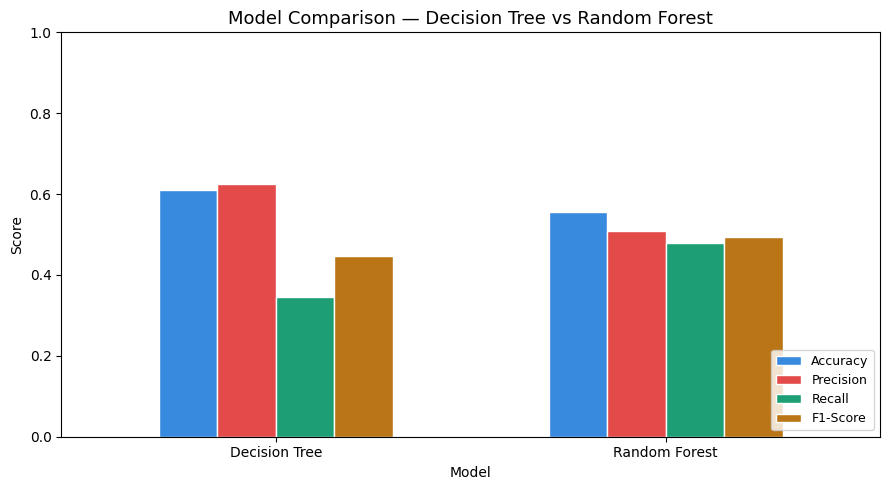


 DECISION TREE — Classification Report 
              precision    recall  f1-score   support

      Missed       0.61      0.83      0.70     14033
        Made       0.63      0.35      0.45     11581

    accuracy                           0.61     25614
   macro avg       0.62      0.59      0.57     25614
weighted avg       0.62      0.61      0.59     25614


 RANDOM FOREST — Classification Report 
              precision    recall  f1-score   support

      Missed       0.59      0.62      0.60     14033
        Made       0.51      0.48      0.49     11581

    accuracy                           0.55     25614
   macro avg       0.55      0.55      0.55     25614
weighted avg       0.55      0.55      0.55     25614



In [ ]:
# Accuracy  : overall % of correct predictions
# Precision : of all shots predicted as made, how many actually were?
# Recall    : of all shots actually made, how many did we catch?
# F1-Score  : balance between precision and recall (best when both matter)

comparison = pd.DataFrame({
    'Model'    : ['Decision Tree', 'Random Forest'],
    'Accuracy' : [accuracy_score(y_test, y_pred_dt),
                  accuracy_score(y_test, y_pred_rf)],
    'Precision': [precision_score(y_test, y_pred_dt),
                  precision_score(y_test, y_pred_rf)],
    'Recall'   : [recall_score(y_test, y_pred_dt),
                  recall_score(y_test, y_pred_rf)],
    'F1-Score' : [f1_score(y_test, y_pred_dt),
                  f1_score(y_test, y_pred_rf)],
}).round(3)

print(" MODEL COMPARISON ")
display(comparison)

# Bar chart comparing all metrics side by side
comparison.set_index('Model').plot(
    kind='bar', figsize=(9, 5),
    color=['#378ADD', '#E24B4A', '#1D9E75', '#BA7517'],
    edgecolor='white', width=0.6
)
plt.title('Model Comparison — Decision Tree vs Random Forest', fontsize=13)
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

# Detailed classification report for each model
print("\n DECISION TREE — Classification Report ")
print(classification_report(y_test, y_pred_dt, target_names=['Missed', 'Made']))

print("\n RANDOM FOREST — Classification Report ")
print(classification_report(y_test, y_pred_rf, target_names=['Missed', 'Made']))

# **4-confusion matrix for models**


---



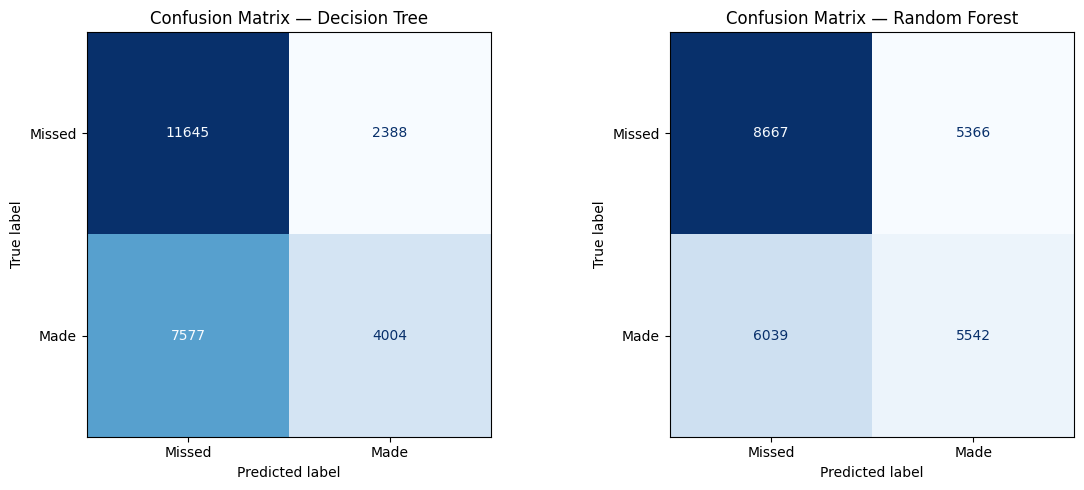

In [ ]:
# Rows = actual result | Columns = predicted result
# Top-left  (TN): correctly predicted missed
# Top-right (FP): predicted made, actually missed
# Bot-left  (FN): predicted missed, actually made
# Bot-right (TP): correctly predicted made

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_dt, y_pred_rf],
    ['Decision Tree', 'Random Forest']
):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Missed', 'Made']).plot(
        ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12)

plt.tight_layout()
plt.show()

# **5-top 3 most important features**


---



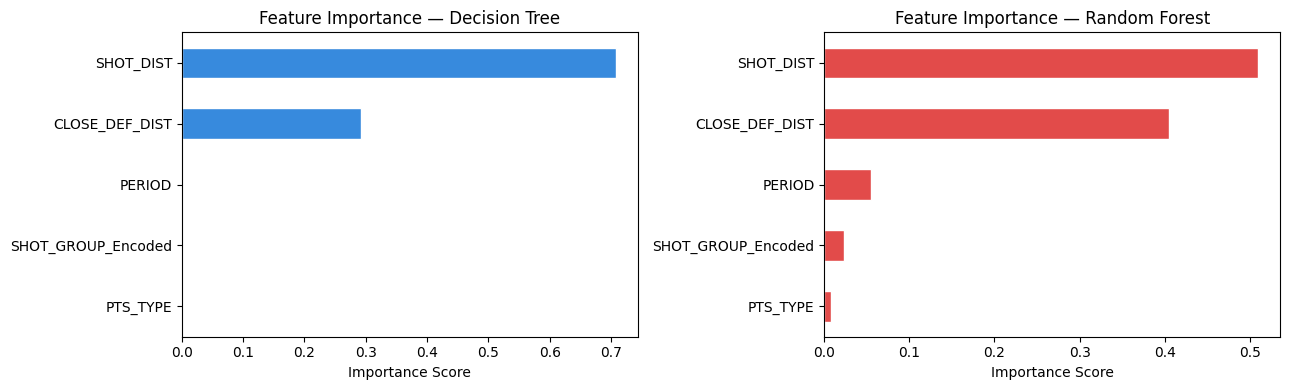

 TOP 3 FEATURES (Decision Tree) 
  1. SHOT_DIST: 0.708
  2. CLOSE_DEF_DIST: 0.292
  3. PTS_TYPE: 0.000

 TOP 3 FEATURES (Random Forest) 
  1. SHOT_DIST: 0.510
  2. CLOSE_DEF_DIST: 0.405
  3. PERIOD: 0.055


In [ ]:
# Feature importance tells us which factors most influence shot success.
# We show both models side by side since they may rank features differently.

dt_imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values()
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dt_imp.plot(kind='barh', ax=axes[0], color='#378ADD', edgecolor='white')
axes[0].set_title('Feature Importance — Decision Tree')
axes[0].set_xlabel('Importance Score')

rf_imp.plot(kind='barh', ax=axes[1], color='#E24B4A', edgecolor='white')
axes[1].set_title('Feature Importance — Random Forest')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

# Print top 3 explicitly
print(" TOP 3 FEATURES (Decision Tree) ")
for i, (feat, score) in enumerate(dt_imp.sort_values(ascending=False).head(3).items(), 1):
    print(f"  {i}. {feat}: {score:.3f}")

print("\n TOP 3 FEATURES (Random Forest) ")
for i, (feat, score) in enumerate(rf_imp.sort_values(ascending=False).head(3).items(), 1):
    print(f"  {i}. {feat}: {score:.3f}")

#**result of comparision**

**Decision Tree** achieved the highest accuracy `(61.1%)` and precision `(0.626)`, meaning that when it predicted a shot would be made, it was correct most of the time. However, `its recall was very low (0.346)`, meaning it missed more than half of all actually made shots. This happened because the model became too conservative — it only predicted "made" when extremely confident.
**Random Forest** achieved` lower accuracy (55.5%)` but a significantly `better F1-Score (0.493) and recall (0.479)`. This means it was more `balanced` — it correctly `identified more made shots without sacrificing too much precision`.

**Which model performed better:**


---



**Random Forest**is the `stronger model overall`. Although **Decision Tree** had higher accuracy, accuracy alone is misleading here because the dataset contains more missed shots than made shots (55% vs 45%). A model that always predicts "missed" would achieve 55% accuracy without learning anything useful. The F1-Score is a more reliable metric in this case because it balances both precision and recall. Random Forest outperformed Decision Tree on F1-Score (0.493 vs 0.446) and recall (0.479 vs 0.346), making it the `better choice for practical shot prediction.`

**Why Random Forest outperformed Decision Tree:**


---


**Decision Tree** builds a `single tree with fixed rules`, which makes it prone to overfitting on the training data. Random Forest builds `100 different trees and combines their votes`, which `reduces overfitting and produces more stable`, generalised predictions. This explains why **Random Forest** performed more consistently across all four metrics despite having lower raw accuracy

# **6-cluster description (Basketball Context)**


---



In [ ]:
cluster_descriptions = {
    'Paint Scorers': {
        'profile' : 'Avg distance: 5.1ft | FG%: 57% | Paint rate: 84% | 3P rate: 1%',
        'context' : 'Centers and power forwards who dominate near the basket. '
                    'Their high FG% comes from short, high-percentage looks. '
                    'Examples: Andre Drummond, DeAndre Jordan.',
        'strategy': 'Best used in pick-and-roll plays or post entry passes.'
    },
    'Three-Point Shooters': {
        'profile' : 'Avg distance: 18.2ft | FG%: 41% | Paint rate: 20% | 3P rate: 52%',
        'context' : 'Shooting guards and small forwards who space the floor. '
                    'Lower FG% but generate high value due to the 3-point bonus. '
                    'Examples: Stephen Curry, Klay Thompson.',
        'strategy': 'Best used as floor spacers to open driving lanes for teammates.'
    },
    'Mid-Range Specialists': {
        'profile' : 'Avg distance: 9.1ft | FG%: 49% | Paint rate: 58% | 3P rate: 4%',
        'context' : 'Guards and forwards who work between the paint and the arc. '
                    'Considered low efficiency in modern NBA analytics. '
                    'Examples: Tyreke Evans, Blake Griffin.',
        'strategy': 'Should be redirected toward paint attempts or three-pointers '
                    'for better offensive efficiency.'
    },
    'Versatile Scorers': {
        'profile' : 'Avg distance: 14.1ft | FG%: 44% | Paint rate: 36% | 3P rate: 27%',
        'context' : 'Star players who score from all zones. Hardest to defend '
                    'because they have no single predictable zone. '
                    'Examples: LeBron James, James Harden.',
        'strategy': 'Most valuable in isolation plays — defenders cannot sag or '
                    'crowd without giving up an open look somewhere.'
    },
}

print(" CLUSTER DESCRIPTIONS in BASKETBALL CONTEXT ")
for cluster, info in cluster_descriptions.items():
    print(f"\n{'─'*55}")
    print(f"  {cluster}")
    print(f"  Profile  : {info['profile']}")
    print(f"  Context  : {info['context']}")
    print(f"  Strategy : {info['strategy']}")

 CLUSTER DESCRIPTIONS in BASKETBALL CONTEXT 

───────────────────────────────────────────────────────
  Paint Scorers
  Profile  : Avg distance: 5.1ft | FG%: 57% | Paint rate: 84% | 3P rate: 1%
  Context  : Centers and power forwards who dominate near the basket. Their high FG% comes from short, high-percentage looks. Examples: Andre Drummond, DeAndre Jordan.
  Strategy : Best used in pick-and-roll plays or post entry passes.

───────────────────────────────────────────────────────
  Three-Point Shooters
  Profile  : Avg distance: 18.2ft | FG%: 41% | Paint rate: 20% | 3P rate: 52%
  Context  : Shooting guards and small forwards who space the floor. Lower FG% but generate high value due to the 3-point bonus. Examples: Stephen Curry, Klay Thompson.
  Strategy : Best used as floor spacers to open driving lanes for teammates.

───────────────────────────────────────────────────────
  Mid-Range Specialists
  Profile  : Avg distance: 9.1ft | FG%: 49% | Paint rate: 58% | 3P rate: 4%
  Context

#**7-coach recommendations**


---



In [ ]:
# Based on model findings and cluster analysis

recommendations = [
    {
        'title'  : 'Avoid contested mid-range shots',
        'finding': 'CLOSE_DEF_DIST was the 2nd most important feature in both models.',
        'action' : 'Players should avoid mid-range shots (8–16ft) with a defender '
                   'within 2 feet — these are the lowest efficiency shots in the dataset.'
    },
    {
        'title'  : 'Prioritise paint attempts',
        'finding': 'Paint Scorers cluster shows 57% FG% vs 41% for perimeter shooters.',
        'action' : 'Coaches should design plays that create high-percentage paint '
                   'opportunities rather than settling for contested jumpers.'
    },
    {
        'title'  : 'Leverage three-point spacing',
        'finding': 'High three-point attempt rates correlate with better overall '
                   'offensive efficiency due to the extra point value.',
        'action' : 'Pair a Paint Scorer with Three-Point Shooters — forces defenders '
                   'to choose between protecting the paint and contesting the arc.'
    },
    {
        'title'  : 'Defender closeout training',
        'finding': 'Shot distance and defender distance together explain over 99% '
                   'of the Decision Tree\'s decisions.',
        'action' : 'Invest in defender closeout drills — even 2 extra feet of space '
                   'significantly increases the opponent\'s made shot probability.'
    },
]

print("\n COACH RECOMMENDATIONS : ")
for i, rec in enumerate(recommendations, 1):
    print(f"\n  Recommendation {i}: {rec['title']}")
    print(f"  Finding : {rec['finding']}")
    print(f"  Action  : {rec['action']}")


 COACH RECOMMENDATIONS : 

  Recommendation 1: Avoid contested mid-range shots
  Finding : CLOSE_DEF_DIST was the 2nd most important feature in both models.
  Action  : Players should avoid mid-range shots (8–16ft) with a defender within 2 feet — these are the lowest efficiency shots in the dataset.

  Recommendation 2: Prioritise paint attempts
  Finding : Paint Scorers cluster shows 57% FG% vs 41% for perimeter shooters.
  Action  : Coaches should design plays that create high-percentage paint opportunities rather than settling for contested jumpers.

  Recommendation 3: Leverage three-point spacing
  Finding : High three-point attempt rates correlate with better overall offensive efficiency due to the extra point value.
  Action  : Pair a Paint Scorer with Three-Point Shooters — forces defenders to choose between protecting the paint and contesting the arc.

  Recommendation 4: Defender closeout training
  Finding : Shot distance and defender distance together explain over 99% of t